# Making Document Extraction Worth Automating

**Avishek Paul Dipto (a1988440) · Programming for AI and ML 2 · University of Adelaide**

A company receives a thousand invoices a month. A model reads them with over 90% of fields correct, yet staff still check almost every one, because nobody knows *which* forty are wrong. High accuracy saves little when the errors cannot be found.

This notebook builds and tests two ideas:

| Goal | Idea |
|---|---|
| **Make fewer errors on unfamiliar layouts** | Train with small random changes to the page and wording, and add a check that the extracted amounts add up. |
| **Find the errors that remain, without labels** | Score each document's risk; send only risky ones to a person. |

**How to run.** Choose a GPU runtime (an A100) and run all cells. Part A builds the code, one small piece at a time; Part B downloads the datasets from their public sources and trains every model, three at a time. On an A100 the full run takes about two and a half hours, and an interrupted run continues where it stopped.

| | Section |
|---|---|
| 0 | Setup |
| **A** | **The code** |
| 1 | How a document is represented |
| 2 | Putting words in reading order |
| 3 | Reading amounts |
| 4 | Varying the training data |
| 5 | Finding documents that share a layout |
| 6 | Loading the datasets |
| 7 | Checking that amounts add up |
| 8 | How often the real labels pass the check |
| 9 | The three models |
| 10 | Feeding documents to a model |
| 11 | Predictions and scores |
| 12 | Training |
| 13 | Deciding which documents need a person |
| 14 | Tables and a document viewer |
| **B** | **The experiments** |
| 15 | Data, layout check and label check |
| 16 | Training runs |
| 17 | Results |

## 0. Setup

| Library | Used for |
|---|---|
| `torch` | numbers on the GPU and training |
| `transformers` | the pretrained models and their tokenizers |
| `datasets` | downloading CORD |
| `docile-benchmark` | reading DocILE and its official scorer |
| `scikit-learn` | grouping documents, nearest neighbours |
| `numpy`, `matplotlib`, `pandas` | arrays, figures, tables |

Colab already has `numpy`, `pandas` and `torch`; their versions are kept as they are, so nothing else on Colab breaks.

**Settings** (the second cell below; the defaults suit an A100):

| Setting | Default | Meaning |
|---|---|---|
| `SAVE_TO_DRIVE` | `True` | Finished runs are kept in your Google Drive under `doc-extraction/runs`. If the session ends, run all cells again: the data is rebuilt in a few minutes and only unfinished runs are trained. Colab asks once for Drive access. |
| `PARALLEL` | 3 on an 80 GB GPU, 2 on 40 GB | how many runs share the GPU at once |
| `DOCILE_TOKEN` | empty | DocILE needs a free token from docile.rossum.ai. Either paste it here, or, better, add it in Colab's **Secrets** panel (key icon on the left) under the name `DOCILE_TOKEN` with *Notebook access* switched on. Without a token, DocILE is skipped and everything else runs. |

In [1]:
!pip freeze | grep -iE '^(numpy|pandas|torch|scipy)==' > /tmp/pins.txt
!pip install -q "transformers>=4.45" "datasets>=2.19" "docile-benchmark>=0.3" scikit-learn matplotlib -c /tmp/pins.txt

# asked through nvidia-smi: the GPU itself is opened only inside the training processes
gpu = !nvidia-smi --query-gpu=name,memory.total --format=csv,noheader,nounits
assert gpu and gpu[0].count(',') == 1, 'Choose a GPU: Runtime → Change runtime type → A100'
GPU_NAME, GPU_GB = gpu[0].split(',')[0], int(gpu[0].split(',')[1]) / 1024
print(f'GPU: {GPU_NAME}, {GPU_GB:.0f} GB')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.1/54.1 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 90.1 MB/s eta 0:00:00
GPU: NVIDIA A100-SXM4-80GB, 80 GB


In [2]:
from pathlib import Path

SAVE_TO_DRIVE = True   # keep finished runs in Google Drive, so a new session continues where the last one stopped
PARALLEL = 3 if GPU_GB >= 60 else 2 if GPU_GB >= 30 else 1   # runs sharing the GPU at once
DOCILE_TOKEN = ''      # or leave empty and use the Colab secret DOCILE_TOKEN (keep the token out of any copy you share)

if not DOCILE_TOKEN:
    try:
        from google.colab import userdata
        DOCILE_TOKEN = userdata.get('DOCILE_TOKEN')
    except Exception as err:  # no such secret, or notebook access not switched on
        print('No DocILE token:', type(err).__name__)
RUN_DOCILE = bool(DOCILE_TOKEN)

DATA, RUNS = Path('data'), Path('runs')
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')   # the Drive of whoever runs the notebook
        saved = Path('/content/drive/MyDrive/doc-extraction/runs')
        saved.mkdir(parents=True, exist_ok=True)
        if not RUNS.exists():
            RUNS.symlink_to(saved)   # 'runs' now points into Drive
    except Exception as err:   # access declined, or not on Colab
        print('Drive not used, so runs are lost if the session ends:', type(err).__name__)
print(f"DocILE: {'included' if RUN_DOCILE else 'skipped'} · runs saved to: {RUNS.resolve()} · {PARALLEL} runs at a time")

Mounted at /content/drive
DocILE: included · runs saved to: /content/drive/MyDrive/doc-extraction/runs · 3 runs at a time


# Part A — the code

## 1. How a document is represented

The three datasets store documents in different ways. The first step turns each into the same simple form, so the rest of the code works on all of them.

| Part | What it is |
|---|---|
| **Word** | One piece of text found on the page, e.g. `TOTAL` |
| **Box** | Where the word sits: left, top, right, bottom, as fractions of the page (0 to 1), so small and large pages compare directly |
| **Field** | One or more words with a meaning, e.g. the total amount |
| **Label** | One per word: `B-name` starts a field, `I-name` continues it, `O` is not part of any field |

Labelling every word turns "find the fields" into "give each word a label", which a model learns well.

**Example.** The line `TOTAL 50,000` has two words. `TOTAL` only names the field, so it is `O`. `50,000` is the value: `B-total.total_price`. Had the amount been read as two words, `50` and `000`, the second would be `I-total.total_price`.

In [3]:
import pickle
from dataclasses import dataclass, field, replace
from pathlib import Path

import numpy as np

OUTSIDE = "O"


@dataclass
class Document:
    """A document as a sequence of OCR words in reading order.

    boxes are (x0, y0, x1, y1) relative to their page, in [0, 1].
    tags are BIO strings ("B-total", "I-total", "O").
    lines give the text-line index of each word, used for key detection
    and number merging.
    """

    doc_id: str
    words: list[str]
    boxes: np.ndarray
    pages: np.ndarray
    lines: np.ndarray
    tags: list[str]
    cluster: int | None = None
    meta: dict = field(default_factory=dict)

    def __len__(self) -> int:
        return len(self.words)

    def copy(self, **changes) -> "Document":
        return replace(self, **changes)


@dataclass(frozen=True)
class Entity:
    """A contiguous run of words carrying one field type."""

    label: str
    start: int
    end: int  # exclusive

    def key(self) -> tuple[str, int, int]:
        return self.label, self.start, self.end

Models work with numbers, so `LabelSpace` numbers the labels: `O` is 0, then `B-` and `I-` for each field in turn. With 30 fields there are 61 labels.

In [4]:
class LabelSpace:
    """Maps field types to BIO label ids and back."""

    def __init__(self, field_types: list[str]):
        self.field_types = list(field_types)
        self.labels = [OUTSIDE] + [f"{p}-{f}" for f in self.field_types for p in ("B", "I")]
        self.label_to_id = {label: i for i, label in enumerate(self.labels)}
        self.field_to_index = {f: i for i, f in enumerate(self.field_types)}

    def __len__(self) -> int:
        return len(self.labels)

    def encode(self, tags: list[str]) -> np.ndarray:
        return np.array([self.label_to_id[t] for t in tags], dtype=np.int64)

    def decode(self, ids) -> list[str]:
        return [self.labels[int(i)] for i in ids]

    def begin_ids(self) -> list[int]:
        """Label id of B-f for every field f, in field order."""
        return [self.label_to_id[f"B-{f}"] for f in self.field_types]

    def inside_ids(self) -> list[int]:
        return [self.label_to_id[f"I-{f}"] for f in self.field_types]

Going back from word labels to fields: `O, B-total, I-total` becomes one field, *total*, covering words 1 and 2. An `I-` label that does not continue the field before it starts a new one.

In [5]:
def tags_to_entities(tags: list[str]) -> list[Entity]:
    """Group BIO tags into entities. An I- tag that does not continue the
    current entity starts a new one, matching the usual lenient decoding."""
    entities: list[Entity] = []
    label, start = None, 0
    for i, tag in enumerate(tags + [OUTSIDE]):
        prefix, _, field_type = tag.partition("-")
        continues = prefix == "I" and field_type == label
        if label is not None and not continues:
            entities.append(Entity(label, start, i))
            label = None
        if prefix in ("B", "I") and not continues:
            label, start = field_type, i
    return entities


def entities_to_tags(entities: list[Entity], n_words: int) -> list[str]:
    tags = [OUTSIDE] * n_words
    for e in entities:
        tags[e.start] = f"B-{e.label}"
        for i in range(e.start + 1, e.end):
            tags[i] = f"I-{e.label}"
    return tags


# ---------------------------------------------------------------- storage

Converted datasets are saved to disk, so each is prepared only once.

In [6]:
def save_split(path: str | Path, dataset: str, field_types: list[str], docs: list[Document]) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "wb") as f:
        pickle.dump({"dataset": dataset, "field_types": field_types, "docs": docs}, f)


def load_split(path: str | Path) -> tuple[str, list[str], list[Document]]:
    with open(path, "rb") as f:
        blob = pickle.load(f)
    return blob["dataset"], blob["field_types"], blob["docs"]

## 2. Putting words in reading order

The OCR software, which reads text from page images, often returns words grouped in blocks. A label such as `Total` and its amount can then end up far apart in the list. Sorting the words the way a person reads, top to bottom and then left to right, keeps them together.

Two words share a line when their vertical centres are less than half a word's height apart.

**Example.** Words with centres at heights 0.100, 0.105 and 0.300 on a page where words are 0.02 tall: the first two differ by 0.005, less than 0.01, so they form line 0; the third starts line 1.

In [7]:
import numpy as np


def reading_order(boxes: np.ndarray, pages: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Order words page by page, top to bottom, then left to right.

    Words are grouped into a line when their vertical centres lie within half
    a typical word height of the line's running centre. OCR engines often
    emit words grouped by block, which mixes rows; this restores row order.

    Returns the permutation and the line id of each word in the new order.
    """
    order: list[int] = []
    line_ids: list[int] = []
    line = 0
    centres = (boxes[:, 1] + boxes[:, 3]) / 2
    heights = boxes[:, 3] - boxes[:, 1]
    for page in np.unique(pages):
        idx = np.flatnonzero(pages == page)
        if idx.size == 0:
            continue
        tolerance = 0.5 * max(float(np.median(heights[idx])), 1e-6)
        current: list[int] = []
        current_centre = 0.0
        for i in idx[np.argsort(centres[idx], kind="stable")]:
            if current and abs(centres[i] - current_centre) > tolerance:
                order.extend(sorted(current, key=lambda j: boxes[j, 0]))
                line_ids.extend([line] * len(current))
                line, current = line + 1, []
            current.append(i)
            current_centre = float(np.mean(centres[current]))
        order.extend(sorted(current, key=lambda j: boxes[j, 0]))
        line_ids.extend([line] * len(current))
        line += 1
    return np.array(order, dtype=np.int64), np.array(line_ids, dtype=np.int64)

Labels are given *after* sorting, so `B-` always marks a field's first word in reading order. The function also counts fields split apart by other words, which happens with text in columns; this is reported later as a measure of data quality.

In [8]:
def build_document(
    doc_id: str,
    words: list[str],
    boxes: np.ndarray,
    pages: np.ndarray,
    entity_ids: list[int],
    entity_labels: dict[int, str],
    cluster: int | None = None,
) -> Document:
    """Create a Document with words sorted into reading order.

    entity_ids[i] is the annotated field instance word i belongs to (-1 for
    none). BIO tags are assigned after sorting, so B always marks the first
    word of a field in reading order.
    """
    boxes = np.clip(np.asarray(boxes, dtype=np.float32), 0.0, 1.0)
    pages = np.asarray(pages, dtype=np.int64)
    order, lines = reading_order(boxes, pages)

    tags, seen, last_pos = [], set(), {}
    fragmented = set()
    for pos, i in enumerate(order):
        eid = entity_ids[i]
        if eid < 0:
            tags.append(OUTSIDE)
            continue
        if eid in seen and last_pos[eid] != pos - 1:
            fragmented.add(eid)  # field broken up by other words in reading order
        tags.append(("I-" if eid in seen else "B-") + entity_labels[eid])
        seen.add(eid)
        last_pos[eid] = pos

    return Document(
        doc_id=doc_id,
        words=[words[i] for i in order],
        boxes=boxes[order],
        pages=pages[order],
        lines=lines,
        tags=tags,
        cluster=cluster,
        meta={"fields": len(seen), "fragmented_fields": len(fragmented)},
    )

**Page jitter.** During training, each page is moved and resized a little at random, by up to a chosen share of the page. All words move together: rows and columns stay intact, but a field never sits at exactly the same spot twice. This stops the model from simply memorising where fields sit on layouts it has seen. Moving words one by one would scramble the lines, which are only about 1.5% of the page apart.

In [9]:
def jitter_boxes(
    boxes: np.ndarray, pages: np.ndarray, magnitude: float, rng: np.random.Generator
) -> np.ndarray:
    """Randomly rescale and shift each page by up to `magnitude` of its size.

    The transform is shared by all words on a page, so relative layout (rows,
    columns, key-value alignment) is preserved while absolute positions, the
    shortcut a model can memorise on repeated templates, never repeat.
    """
    if magnitude <= 0:
        return boxes
    out = boxes.astype(np.float32, copy=True)
    for page in np.unique(pages):
        mask = pages == page
        b = 0.5 + (out[mask] - 0.5) * rng.uniform(1 - magnitude, 1 + magnitude)
        low, high = b[:, :2].min(axis=0), b[:, 2:].max(axis=0)
        t_min = np.maximum(-magnitude, -low)
        t_max = np.maximum(t_min, np.minimum(magnitude, 1 - high))
        shift = rng.uniform(t_min, t_max)
        b[:, [0, 2]] += shift[0]
        b[:, [1, 3]] += shift[1]
        out[mask] = np.clip(b, 0.0, 1.0)
    return out


def union_box(boxes: np.ndarray) -> tuple[float, float, float, float]:
    return (
        float(boxes[:, 0].min()),
        float(boxes[:, 1].min()),
        float(boxes[:, 2].max()),
        float(boxes[:, 3].max()),
    )

## 3. Reading amounts

The check in Section 7 needs the value of every number on the page, and documents write numbers in different ways:

| Written | Value |
|---|---|
| `1,234.56` | 1234.56 |
| `1.234,56` (European style) | 1234.56 |
| `45,000` (Indonesian receipts) | 45000 |
| `12,50` | 12.5 |
| `(5.00)` or `5.00-` | −5 |
| `12.03.2021`, `21%`, `12:30` | not an amount |

The rule: if both `,` and `.` appear, the last one is the decimal point. If only one appears, it separates thousands when exactly three digits follow it, and is the decimal point otherwise. Thousand groups must have exactly three digits, which rules out dates.

In [10]:
import re

import numpy as np


_EDGE_NOISE = re.compile(r"^[^\d(+-]+|[^\d)-]+$")  # currency symbols, letters, colons at the edges
_NUMBER = re.compile(r"^[-+(]?\d[\d.,' ]*[)-]?$")
_LEADING_GROUP = re.compile(r"^[-+(]?\d{1,3}$")
_THOUSANDS_TAIL = re.compile(r"^\d{3}(?:[.,]\d{1,2})?\D*$")


def parse_amount(text: str) -> float | None:
    if "%" in text or "/" in text or ":" in text.strip(": "):
        return None
    s = _EDGE_NOISE.sub("", text.strip())
    if not s or not _NUMBER.match(s):
        return None

    negative = s.startswith("-") or s.endswith("-") or (s.startswith("(") and s.endswith(")"))
    s = s.strip("+-()").replace("'", "").replace(" ", "")
    if not s or not s[0].isdigit() or not s[-1].isdigit():
        return None

    separators = [c for c in s if c in ".,"]
    if not separators:
        number = s
    elif len(set(separators)) == 2:
        decimal = "." if s.rfind(".") > s.rfind(",") else ","
        thousands = "," if decimal == "." else "."
        integer, _, fraction = s.rpartition(decimal)
        if not _valid_groups(integer, thousands):
            return None
        number = integer.replace(thousands, "") + "." + fraction
    else:
        sep = separators[0]
        parts = s.split(sep)
        if len(parts) > 2 or len(parts[-1]) == 3:
            # one or more thousands separators, e.g. "45,000" or "1.234.567"
            if not _valid_groups(s, sep):
                return None
            number = s.replace(sep, "")
        else:
            number = parts[0] + "." + parts[1]
    try:
        value = float(number)
    except ValueError:
        return None
    return -value if negative else value


def _valid_groups(integer: str, sep: str) -> bool:
    groups = integer.split(sep)
    return 1 <= len(groups[0]) <= 3 and all(len(g) == 3 for g in groups[1:])

Sometimes `1 234,56` is read as two words. When a word of one to three digits is followed on the same line by one starting with three digits, the two are read together and the value is put on the second word. Adding up the values of a field's words then still gives the right amount.

In [11]:
def word_values(doc: Document) -> np.ndarray:
    """Numeric value of each word, 0 where the word is not an amount.

    OCR often splits "1 234,56" into two words. When a 1-3 digit word is
    followed on the same line by a word starting with a 3-digit group, the
    pair is parsed together and the value is placed on the second word,
    so summing values over a labelled span still gives the right amount.
    """
    values = np.zeros(len(doc), dtype=np.float32)
    for i, word in enumerate(doc.words):
        value = parse_amount(word)
        values[i] = 0.0 if value is None else value

    for i in range(len(doc) - 1):
        if (
            doc.lines[i] == doc.lines[i + 1]
            and _LEADING_GROUP.match(doc.words[i])
            and _THOUSANDS_TAIL.match(doc.words[i + 1])
            and _horizontal_gap(doc.boxes[i], doc.boxes[i + 1]) < doc.boxes[i, 3] - doc.boxes[i, 1]
        ):
            merged = parse_amount(doc.words[i] + doc.words[i + 1])
            if merged is not None:
                values[i], values[i + 1] = 0.0, merged
    return values


def span_value(doc: Document, values: np.ndarray, start: int, end: int) -> float:
    """Value of an entity: the sum of its word values."""
    return float(values[start:end].sum())


def _horizontal_gap(left: np.ndarray, right: np.ndarray) -> float:
    return float(right[0] - left[2])

## 4. Varying the training data

Documents print a **key** before most values: `Total:`, `Amount due`, `Celkem`. A model can learn to rely on one exact key and fail when another company writes it differently.

Neither dataset marks keys, so a key is taken to be the words just left of a value on the same line, if they contain letters and no digits.

In [12]:
from collections import Counter, defaultdict

import numpy as np


MAX_KEY_WORDS = 4  # keys longer than this are rare and usually a mis-detection
MIN_KEY_COUNT = 2  # a phrase must recur to enter the vocabulary


def find_key_spans(doc: Document) -> list[tuple[int, int, str]]:
    """(start, end, field_type) of the key phrase preceding each field."""
    spans = []
    for entity in tags_to_entities(doc.tags):
        line = doc.lines[entity.start]
        start = entity.start
        while (
            start > 0
            and entity.start - start < MAX_KEY_WORDS
            and doc.lines[start - 1] == line
            and doc.tags[start - 1] == OUTSIDE
            and not any(c.isdigit() for c in doc.words[start - 1])
        ):
            start -= 1
        phrase = doc.words[start : entity.start]
        if phrase and any(c.isalpha() for w in phrase for c in w):
            spans.append((start, entity.start, entity.label))
    return spans

Collecting every key seen at least twice, per field, gives a list of real wordings: for the total, `TOTAL`, `GRAND TOTAL`, `Total Due`, and so on.

In [13]:
def key_vocabulary(docs: list[Document]) -> dict[str, list[tuple[str, ...]]]:
    counts: dict[str, Counter] = defaultdict(Counter)
    for doc in docs:
        for start, end, field_type in find_key_spans(doc):
            counts[field_type][tuple(doc.words[start:end])] += 1
    return {f: [phrase for phrase, n in c.most_common() if n >= MIN_KEY_COUNT] for f, c in counts.items()}

With a chosen probability, each key is replaced by another wording of the same field. The new words take the old key's place, sharing its width by length.

**Example.** `TOTAL 60,500` can become `GRAND TOTAL 60,500`. The amount and its label stay the same, so the model learns to find the total whichever wording is used.

In [14]:
def swap_keys(doc: Document, vocab: dict, prob: float, rng: np.random.Generator) -> Document:
    """Replace each detected key, with probability `prob`, by another phrase
    of the same field. New words share the old key's box, split by length."""
    words, boxes = list(doc.words), doc.boxes
    pages, lines, tags = doc.pages, doc.lines, list(doc.tags)
    for start, end, field_type in reversed(find_key_spans(doc)):
        options = [p for p in vocab.get(field_type, []) if list(p) != doc.words[start:end]]
        if not options or rng.random() >= prob:
            continue
        phrase = list(options[rng.integers(len(options))])
        new_boxes = _split_box(union_box(boxes[start:end]), phrase)
        n = len(phrase)
        words[start:end] = phrase
        tags[start:end] = [OUTSIDE] * n
        boxes = np.concatenate([boxes[:start], new_boxes, boxes[end:]])
        pages = np.concatenate([pages[:start], np.full(n, pages[start]), pages[end:]])
        lines = np.concatenate([lines[:start], np.full(n, lines[start]), lines[end:]])
    return doc.copy(words=words, boxes=boxes, pages=pages, lines=lines, tags=tags)


def _split_box(box: tuple, words: list[str]) -> np.ndarray:
    x0, y0, x1, y1 = box
    widths = np.array([len(w) + 1 for w in words], dtype=np.float32)
    edges = x0 + (x1 - x0) * np.concatenate([[0], np.cumsum(widths) / widths.sum()])
    return np.array([(edges[i], y0, edges[i + 1], y1) for i in range(len(words))], dtype=np.float32)

`Augmenter` applies both changes, key swapping and page jitter, to a training document. It is used only while training, never when testing.

In [15]:
class Augmenter:
    """Applies the configured augmentations to a training document."""

    def __init__(self, jitter: float, key_swap: float, vocab: dict | None = None):
        self.jitter = jitter
        self.key_swap = key_swap
        self.vocab = vocab or {}

    def __call__(self, doc: Document, rng: np.random.Generator) -> Document:
        if self.key_swap > 0 and self.vocab:
            doc = swap_keys(doc, self.vocab, self.key_swap, rng)
        if self.jitter > 0:
            doc = doc.copy(boxes=jitter_boxes(doc.boxes, doc.pages, self.jitter, rng))
        return doc

## 5. Finding documents that share a layout

Receipts from the same shop look alike: same header, same wording, same arrangement. If the test set contains shops that also appear in training, a model can score well by remembering where things sit, and the score says little about new shops. Laatiri et al. (2023) found this in three of every four test documents of the SROIE dataset.

**How shops are recognised.** Each document is described by the words in its first five lines (usually the shop's name and address) and by its keys. Which fields appear is deliberately left out: almost every receipt has a total and a tax line, so that would make all shops look alike. An earlier version made exactly this mistake and wrongly found most of WildReceipt's new shops in training.

**How alike two documents are.** The share of words they do *not* have in common:

$$\text{distance} = 1 - \frac{\text{words in both}}{\text{words in either}}$$

**Example.** `{safeway, grocery, total}` and `{safeway, total}` share 2 of 3 words: distance 1 − 2/3 = 0.33.

Documents are then grouped step by step, always joining the closest groups first, until the remaining groups are further apart than a set threshold. Each group is one layout.

In [16]:
import json
import re
from pathlib import Path

import numpy as np
from sklearn.cluster import AgglomerativeClustering


DISTANCE_THRESHOLD = 0.5  # Jaccard distance below which two documents share a template
HEADER_LINES = 5  # text lines at the top that identify the source
CALIBRATION_THRESHOLDS = (0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)


def template_signature(doc: Document) -> set[str]:
    """Header words (letters only, 3+ characters) plus key phrases."""
    signature = set()
    for word, line in zip(doc.words, doc.lines):
        if line - doc.lines[0] >= HEADER_LINES:
            break
        token = re.sub(r"[^a-z]", "", word.lower())
        if len(token) >= 3:
            signature.add(f"header:{token}")
    for start, end, field_type in find_key_spans(doc):
        signature.add(f"key:{field_type}:{' '.join(doc.words[start:end]).lower()}")
    return signature


def signature_distances(docs: list[Document]) -> np.ndarray:
    """Pairwise Jaccard distance between template signatures."""
    signatures = [template_signature(d) for d in docs]
    vocab = {token: i for i, token in enumerate(sorted(set().union(*signatures)))}
    x = np.zeros((len(docs), max(len(vocab), 1)), dtype=np.float32)
    for row, sig in enumerate(signatures):
        x[row, [vocab[t] for t in sig]] = 1.0
    inter = x @ x.T
    sizes = x.sum(axis=1)
    union = sizes[:, None] + sizes[None, :] - inter
    return 1.0 - inter / np.maximum(union, 1.0)


def cluster(distance: np.ndarray, threshold: float = DISTANCE_THRESHOLD) -> np.ndarray:
    model = AgglomerativeClustering(
        n_clusters=None, metric="precomputed", linkage="average", distance_threshold=threshold
    )
    return model.fit_predict(distance)


def cluster_templates(docs: list[Document], threshold: float = DISTANCE_THRESHOLD) -> np.ndarray:
    return cluster(signature_distances(docs), threshold)

With layouts known, the code can measure how many test documents share a layout with training (the **reuse rate**), and can build splits where no layout appears on both sides. `seen_template_holdout` does the opposite: it picks documents whose layout *does* stay in training, to measure accuracy on familiar layouts.

In [17]:
def replication_rate(train_clusters: np.ndarray, test_clusters: np.ndarray) -> float:
    """Share of test documents whose template also occurs in training."""
    return float(np.isin(test_clusters, train_clusters).mean())


def disjoint_split(clusters: np.ndarray, sizes: dict[str, int], seed: int = 0) -> dict[str, np.ndarray]:
    """Assign whole clusters, in random order, to the first split in `sizes`
    that still has room for all of them; the last split takes the rest."""
    rng = np.random.default_rng(seed)
    names = list(sizes)
    assignment = {name: [] for name in names}
    for c in rng.permutation(np.unique(clusters)):
        members = np.flatnonzero(clusters == c).tolist()
        target = next((n for n in names[:-1] if len(assignment[n]) + len(members) <= sizes[n]), names[-1])
        assignment[target].extend(members)
    empty = [n for n, idx in assignment.items() if not idx]
    if empty:
        raise ValueError(f"no template fits split(s) {empty}; lower the distance threshold")
    return {name: np.array(sorted(idx), dtype=np.int64) for name, idx in assignment.items()}


def seen_template_holdout(clusters: np.ndarray, size: int, seed: int = 0) -> np.ndarray:
    """Pick up to `size` documents whose template stays represented in the
    rest: from every cluster with two or more members, all but one are
    candidates. Gives a validation set of seen layouts."""
    rng = np.random.default_rng(seed)
    candidates = []
    for c in np.unique(clusters):
        members = rng.permutation(np.flatnonzero(clusters == c))
        candidates.extend(members[1:].tolist())
    chosen = rng.permutation(candidates)[:size]
    return np.sort(chosen).astype(np.int64)

**Choosing the threshold.** WildReceipt's authors guarantee that its test shops never appear in training, so on WildReceipt the correct threshold should find almost no reuse. `calibrate` measures reuse at several thresholds; the chosen one (0.5) is the loosest that keeps WildReceipt's reuse near zero.

In [18]:
def calibrate(train: list[Document], test: list[Document]) -> list[dict]:
    """Templates found and test replication at each threshold. On a split
    whose test templates are known to be unseen, the right threshold is the
    loosest one that keeps replication near zero."""
    distance = signature_distances(train + test)
    rows = []
    for threshold in CALIBRATION_THRESHOLDS:
        clusters = cluster(distance, threshold)
        train_c, test_c = clusters[: len(train)], clusters[len(train):]
        sizes = np.bincount(train_c)
        rows.append({
            "threshold": threshold,
            "templates": int(len(np.unique(clusters))),
            "test_replication": replication_rate(train_c, test_c),
            "train_docs_in_shared_templates": float((sizes[train_c] >= 2).mean()),
        })
    return rows

## 6. Loading the datasets

| Dataset | Documents | Fields | Familiar vs new layouts | Source |
|---|---|---|---|---|
| **CORD** | 1,000 receipts | 30 | built here (Section 5) | Hugging Face |
| **WildReceipt** | 1,740 receipts | 12 | test shops are new by design | OpenMMLab |
| **DocILE** | 5,680 invoices | 55 | official layout groups | DocILE, free token |

Each loader produces the documents of Section 1.

**CORD.** Each line of a receipt has a category. Words marked as keys become `O`, so only values are targets, as in the other datasets.

In [19]:
import json

import numpy as np


HF_NAME = "naver-clova-ix/cord-v2"
SPLITS = ("train", "validation", "test")


def parse_cord_record(doc_id: str, ground_truth: str) -> Document:
    gt = json.loads(ground_truth)
    size = gt["meta"]["image_size"]
    width, height = float(size["width"]), float(size["height"])

    words, boxes, entity_ids, labels = [], [], [], {}
    for eid, line in enumerate(gt["valid_line"]):
        labels[eid] = line["category"]
        for word in line["words"]:
            text = word["text"].strip()
            if not text:
                continue
            q = word["quad"]
            xs, ys = (q["x1"], q["x2"], q["x3"], q["x4"]), (q["y1"], q["y2"], q["y3"], q["y4"])
            words.append(text)
            boxes.append((min(xs) / width, min(ys) / height, max(xs) / width, max(ys) / height))
            entity_ids.append(-1 if word.get("is_key") else eid)

    return build_document(
        doc_id, words, np.array(boxes).reshape(-1, 4), np.zeros(len(words)), entity_ids, labels
    )


def load_cord() -> dict[str, list[Document]]:
    from datasets import load_dataset

    out = {}
    for split in SPLITS:
        ds = load_dataset(HF_NAME, split=split).remove_columns("image")
        out[split] = [parse_cord_record(f"{split}_{i:04d}", r["ground_truth"]) for i, r in enumerate(ds)]
    return out

**WildReceipt.** Each text box is one of 25 classes: a value or a key for 12 fields, or *other*. Value boxes become fields; keys and *other* become `O`. The text has its spaces removed (`THANKYOU`), so each box is treated as one word.

In [20]:
import json
from pathlib import Path

import numpy as np


VALUE_SUFFIX = "_value"


def read_classes(path: Path) -> dict[int, str]:
    classes = {}
    for line in path.read_text().splitlines():
        if line.strip():
            idx, name = line.split(maxsplit=1)
            classes[int(idx)] = name.strip()
    return classes


def wildreceipt_field_types(classes: dict[int, str]) -> list[str]:
    return sorted(n[: -len(VALUE_SUFFIX)] for n in classes.values() if n.endswith(VALUE_SUFFIX))


def parse_wildreceipt_record(doc_id: str, record: dict, classes: dict[int, str]) -> Document:
    width, height = float(record["width"]), float(record["height"])
    words, boxes, entity_ids, labels = [], [], [], {}
    for i, box in enumerate(record["annotations"]):
        text = box["text"].strip()
        if not text:
            continue
        xs, ys = box["box"][0::2], box["box"][1::2]
        words.append(text)
        boxes.append((min(xs) / width, min(ys) / height, max(xs) / width, max(ys) / height))
        name = classes.get(int(box["label"]), "")
        if name.endswith(VALUE_SUFFIX):
            labels[i] = name[: -len(VALUE_SUFFIX)]
            entity_ids.append(i)
        else:
            entity_ids.append(-1)
    return build_document(
        doc_id, words, np.array(boxes).reshape(-1, 4), np.zeros(len(words)), entity_ids, labels
    )


def load_wildreceipt(root: str | Path) -> tuple[dict[str, list[Document]], list[str]]:
    root = Path(root)
    classes = read_classes(root / "class_list.txt")
    splits = {}
    for split in ("train", "test"):
        lines = (root / f"{split}.txt").read_text().splitlines()
        splits[split] = [
            parse_wildreceipt_record(f"{split}_{i:04d}", json.loads(line), classes) for i, line in enumerate(lines) if line
        ]
    return splits, wildreceipt_field_types(classes)

**DocILE.** Fields and words come as separate boxes. A word belongs to a field when at least half of the word lies inside the field's box. When a word falls inside two fields, it takes the one it overlaps most, and these cases are counted.

In [21]:
from collections import Counter

import numpy as np


MIN_OVERLAP = 0.5


def docile_field_types() -> list[str]:
    from docile.dataset import KILE_FIELDTYPES, LIR_FIELDTYPES

    return list(KILE_FIELDTYPES) + list(LIR_FIELDTYPES)


def _page_words(document, page: int):
    try:
        return document.ocr.get_all_words(page, snapped=True)
    except ValueError:  # snapped boxes not cached and no page image available
        return document.ocr.get_all_words(page, snapped=False)


def _overlap_ratio(words: np.ndarray, fields: np.ndarray) -> np.ndarray:
    """Share of each word's area inside each field box, shape (words, fields)."""
    left = np.maximum(words[:, None, 0], fields[None, :, 0])
    top = np.maximum(words[:, None, 1], fields[None, :, 1])
    right = np.minimum(words[:, None, 2], fields[None, :, 2])
    bottom = np.minimum(words[:, None, 3], fields[None, :, 3])
    inter = np.clip(right - left, 0, None) * np.clip(bottom - top, 0, None)
    area = np.clip((words[:, 2] - words[:, 0]) * (words[:, 3] - words[:, 1]), 1e-9, None)
    return inter / area[:, None]

One document at a time: for each page, find the field each word overlaps most, then put the words in reading order.

In [22]:
def convert_document(document) -> tuple[Document, Counter]:
    stats: Counter = Counter()
    annotation = document.annotation
    fields = annotation.fields + annotation.li_fields
    labels = {i: f.fieldtype for i, f in enumerate(fields)}

    words, boxes, pages, entity_ids = [], [], [], []
    for page in range(document.page_count):
        page_words = [w for w in _page_words(document, page) if w.text and w.text.strip()]
        if not page_words:
            continue
        word_boxes = np.array([w.bbox.to_tuple() for w in page_words], dtype=np.float32)
        field_idx = [i for i, f in enumerate(fields) if f.page == page]
        assigned = np.full(len(page_words), -1)
        if field_idx:
            field_boxes = np.array([fields[i].bbox.to_tuple() for i in field_idx], dtype=np.float32)
            ratio = _overlap_ratio(word_boxes, field_boxes)
            hits = ratio >= MIN_OVERLAP
            for w in np.flatnonzero(hits.any(axis=1)):
                candidates = {labels[field_idx[j]] for j in np.flatnonzero(hits[w])}
                stats["conflicting_words"] += len(candidates) > 1
                assigned[w] = field_idx[int(ratio[w].argmax())]
        words += [w.text.strip() for w in page_words]
        boxes.append(word_boxes)
        pages += [page] * len(page_words)
        entity_ids += assigned.tolist()

    covered = set(entity_ids)
    stats["fields"] += len(fields)
    stats["fields_without_words"] += sum(i not in covered for i in labels)
    stats["labelled_words"] += sum(e >= 0 for e in entity_ids)
    stats["words"] += len(words)

    doc = build_document(
        document.docid,
        words,
        np.concatenate(boxes) if boxes else np.zeros((0, 4), np.float32),
        np.array(pages),
        entity_ids,
        labels,
        cluster=annotation.cluster_id,
    )
    return doc, stats


def load_docile(path: str, split: str) -> tuple[list[Document], Counter]:
    from docile.dataset import CachingConfig, Dataset
    from tqdm import tqdm

    dataset = Dataset(split, path, load_annotations=False, load_ocr=False, cache_images=CachingConfig.OFF)
    docs, stats = [], Counter()
    for document in tqdm(dataset, desc=f"DocILE {split}"):
        with document:
            doc, doc_stats = convert_document(document)
        docs.append(doc)
        stats.update(doc_stats)
    return docs, stats


# ------------------------------------------------------- official evaluation

DocILE's official scorer compares fields by *position*, so each predicted field is turned back into one box around its words.

In [23]:
def to_kile_fields(doc: Document, entities: list[Entity], scores: list[float]):
    """Convert predicted entities to DocILE Fields (KILE field types only).

    The evaluator matches fields by location, so each entity becomes the
    union box of its words on the page where it starts.
    """
    from docile.dataset import KILE_FIELDTYPES, BBox, Field

    kile = set(KILE_FIELDTYPES)
    out = []
    for entity, score in zip(entities, scores):
        if entity.label not in kile:
            continue
        idx = np.arange(entity.start, entity.end)
        idx = idx[doc.pages[idx] == doc.pages[entity.start]]
        out.append(
            Field(
                bbox=BBox(*union_box(doc.boxes[idx])),
                page=int(doc.pages[entity.start]),
                score=float(score),
                fieldtype=entity.label,
            )
        )
    return out

These functions download and convert each dataset once. For CORD they also build a split with no shared layouts. For WildReceipt they set aside 100 training receipts from shops that stay in training, giving one set of familiar layouts (validation) and one of new layouts (test). The difference between the two scores is the **layout gap**:

$$\Delta = F_1(\text{familiar layouts}) - F_1(\text{new layouts})$$

In [24]:
import json
from pathlib import Path

import numpy as np


def field_types_of(docs) -> list[str]:
    return sorted({e.label for d in docs for e in tags_to_entities(d.tags)})


def prepare_cord(out: Path) -> None:

    splits = load_cord()
    types = field_types_of([d for docs in splits.values() for d in docs])
    for name, docs in splits.items():
        save_split(out / "cord" / f"{name}.pkl", "cord", types, docs)
        print(f"cord/{name}: {len(docs)} documents")

**CORD without shared layouts.** All 1,000 receipts are grouped by layout, and whole groups are dealt to test, validation and training, so no layout appears in two places. The report also gives the reuse rate of CORD's official split.

In [25]:
def prepare_cord_disjoint(out: Path, seed: int, threshold: float) -> None:

    splits = {name: load_split(out / "cord" / f"{name}.pkl") for name in ("train", "validation", "test")}
    _, types, _ = splits["train"]
    docs = [d for name in splits for d in splits[name][2]]
    clusters = cluster_templates(docs, threshold)
    for doc, c in zip(docs, clusters):
        doc.cluster = int(c)

    n_train = len(splits["train"][2])
    n_val = len(splits["validation"][2])
    official = {"train": clusters[:n_train], "test": clusters[n_train + n_val :]}
    sizes = {"test": len(splits["test"][2]), "validation": n_val, "train": len(docs)}
    assignment = disjoint_split(clusters, sizes, seed)

    report = {
        "threshold": threshold,
        "templates": int(len(np.unique(clusters))),
        "official_test_replication": replication_rate(official["train"], official["test"]),
        "disjoint_test_replication": replication_rate(
            clusters[assignment["train"]], clusters[assignment["test"]]
        ),
        "sizes": {k: int(len(v)) for k, v in assignment.items()},
    }
    # official splits keep the same cluster ids, so x-shot analysis works on both
    for name, (_, _, split_docs) in splits.items():
        save_split(out / "cord" / f"{name}.pkl", "cord", types, split_docs)
    for name, idx in assignment.items():
        save_split(out / "cord_disjoint" / f"{name}.pkl", "cord", types, [docs[i] for i in idx])
    (out / "cord_disjoint" / "split_report.json").write_text(json.dumps(report, indent=2))
    print(json.dumps(report, indent=2))

**WildReceipt.** The official test set already has only new shops; 100 training receipts from shops that stay in training become the familiar-layout set.

In [26]:
def prepare_wildreceipt(raw: str, out: Path, seed: int, threshold: float, validation_size: int = 100) -> None:
    """WildReceipt's test templates are unseen by design. A validation set of
    seen templates is held out from training, so
    Δ = F1(validation, seen layouts) - F1(test, unseen layouts)."""

    splits, types = load_wildreceipt(raw)
    train, test = splits["train"], splits["test"]
    clusters = cluster_templates(train + test, threshold)
    for doc, c in zip(train + test, clusters):
        doc.cluster = int(c)
    train_clusters = clusters[: len(train)]
    held = set(seen_template_holdout(train_clusters, validation_size, seed).tolist())

    out_splits = {
        "train": [d for i, d in enumerate(train) if i not in held],
        "validation": [d for i, d in enumerate(train) if i in held],
        "test": test,
    }
    keep = np.array([i not in held for i in range(len(train))])
    report = {
        "threshold": threshold,
        "templates": int(len(np.unique(clusters))),
        # near 0 if our key-based clusters agree with the authors' unseen-template test
        "test_replication": replication_rate(train_clusters[keep], clusters[len(train):]),
        "validation_replication": replication_rate(train_clusters[keep], train_clusters[~keep]),
        "sizes": {k: len(v) for k, v in out_splits.items()},
    }
    for name, docs in out_splits.items():
        save_split(out / "wildreceipt" / f"{name}.pkl", "wildreceipt", types, docs)
    (out / "wildreceipt" / "split_report.json").write_text(json.dumps(report, indent=2))
    print(json.dumps(report, indent=2))

**DocILE.** Converts the official training and validation sets and records how many words fell inside two fields or none.

In [27]:
def prepare_docile(docile_path: str, out: Path) -> None:

    for split in ("train", "val"):
        docs, stats = load_docile(docile_path, split)
        save_split(out / "docile" / f"{split}.pkl", "docile", docile_field_types(), docs)
        print(f"docile/{split}: {len(docs)} documents, {dict(stats)}")
        (out / "docile" / f"{split}_labelling.json").write_text(json.dumps(dict(stats), indent=2))

## 7. Checking that amounts add up

This is the project's main idea. A normal model learns each word's label on its own; nothing tells it that the items, tax and total of a receipt must agree. Here, that rule becomes part of training.

**Turning the rule into a number.** The numbers on the page are fixed; only the labels are uncertain. If the model is 70% sure a word is the total, that word counts 70% towards the total. Adding this up over all words gives the model's **expected total**:

$$\text{expected value of a field} = \sum_{\text{words}} P(\text{word is in the field}) \times \text{word's value}$$

Because this changes smoothly with the model's probabilities, training can reduce any mismatch.

**Example.** Items 25,000 and 5,000, tax 3,000, total 33,000. The model is 50% sure the real total is the total, and also 50% sure, wrongly, that the 25,000 item is. Its expected total is 0.5 × 33,000 + 0.5 × 25,000 = 29,000, while items plus tax give 33,000: a 12% mismatch. Training lowers it by moving belief away from the item price.

In [28]:
from collections import Counter
from dataclasses import dataclass

import numpy as np
import torch
import torch.nn.functional as F


REL_TOLERANCE = 0.01  # rounding on printed amounts; residuals below 1% count as satisfied
MAX_VALUE_RATIO = 10.0  # cap on |value / total|; IDs and dates parsed as numbers stay bounded
SINGLETON_SHARE = 0.95  # a field is "at most once" if this share of documents agree
HUBER_BETA = 0.05  # quadratic below a 5% relative residual, linear above: bounded gradients


@dataclass(frozen=True)
class Equation:
    """sum of S(part) == S(total). parts[0] is the principal term (items,
    subtotal or net); the others (tax, service) may be absent."""

    name: str
    parts: tuple[str, ...]
    total: str


EQUATIONS: dict[str, list[Equation]] = {
    "cord": [
        Equation("items=subtotal", ("menu.price",), "sub_total.subtotal_price"),
        Equation(
            "items+tax+service=total",
            ("menu.price", "sub_total.tax_price", "sub_total.service_price"),
            "total.total_price",
        ),
        Equation(
            "subtotal+tax+service=total",
            ("sub_total.subtotal_price", "sub_total.tax_price", "sub_total.service_price"),
            "total.total_price",
        ),
    ],
    "wildreceipt": [
        Equation("items=subtotal", ("Prod_price",), "Subtotal"),
        Equation("items+tax+tips=total", ("Prod_price", "Tax", "Tips"), "Total"),
        Equation("subtotal+tax+tips=total", ("Subtotal", "Tax", "Tips"), "Total"),
    ],
    "docile": [
        Equation("net_items+tax=gross", ("line_item_amount_net", "amount_total_tax"), "amount_total_gross"),
        Equation("gross_items=gross", ("line_item_amount_gross",), "amount_total_gross"),
        Equation("net+tax=gross", ("amount_total_net", "amount_total_tax"), "amount_total_gross"),
    ],
}

Only rules whose fields exist in the dataset are used. `coefficient_matrix` writes each rule as +1 for the parts and −1 for the total, so all rules can be checked in one step.

In [29]:
def equations_for(dataset: str, label_space: LabelSpace) -> list[Equation]:
    """The dataset's equations whose fields all exist in the label space."""
    known = set(label_space.field_types)
    return [e for e in EQUATIONS.get(dataset, []) if {e.total, *e.parts} <= known]


def coefficient_matrix(equations: list[Equation], label_space: LabelSpace) -> torch.Tensor:
    """(equations, fields) matrix: +1 for parts, -1 for the total."""
    c = torch.zeros(len(equations), len(label_space.field_types))
    for k, e in enumerate(equations):
        for f in e.parts:
            c[k, label_space.field_to_index[f]] = 1.0
        c[k, label_space.field_to_index[e.total]] = -1.0
    return c


# ------------------------------------------------------------ ground truth

**Which receipts to use.** Some receipts do not add up even with correct labels (discounts, rounding, reading errors). The rule is applied only to receipts whose correct labels pass it, with a 1% allowance for rounding.

In [30]:
def field_sums(entities: list[Entity], values: np.ndarray) -> dict[str, float]:
    sums: dict[str, float] = Counter()
    for e in entities:
        sums[e.label] += float(values[e.start : e.end].sum())
    return sums


def equation_status(entities: list[Entity], values: np.ndarray, equations: list[Equation]):
    """For each equation: (applicable, satisfied, scale).

    An equation applies when its total and principal part are present;
    the residual is measured relative to the total.
    """
    present = {e.label for e in entities}
    sums = field_sums(entities, values)
    out = []
    for eq in equations:
        scale = abs(sums.get(eq.total, 0.0))
        applicable = eq.total in present and eq.parts[0] in present and scale > 0
        residual = sum(sums.get(p, 0.0) for p in eq.parts) - sums.get(eq.total, 0.0)
        satisfied = applicable and abs(residual) <= REL_TOLERANCE * scale
        out.append((applicable, satisfied, scale))
    return out

**The second rule.** Key fields such as the total appear at most once. A field counts as "at most once" when 95% of training documents agree. Missing fields are fine: not every invoice has a due date.

In [31]:
def singleton_fields(docs: list[Document]) -> list[str]:
    """Fields that appear at most once in at least SINGLETON_SHARE of the
    training documents that contain them."""
    present, at_most_once = Counter(), Counter()
    for doc in docs:
        counts = Counter(e.label for e in tags_to_entities(doc.tags))
        for f, n in counts.items():
            present[f] += 1
            at_most_once[f] += n == 1
    return sorted(f for f in present if at_most_once[f] >= SINGLETON_SHARE * present[f])


# -------------------------------------------------------------- the loss

**The penalty added to training.**

| Part | What it penalises |
|---|---|
| Sum rule | the mismatch between expected parts and expected total, as a share of the total |
| Once rule | any expected count above one for a field that appears at most once |

Choices that keep it stable:
- Each word's value is divided by the document's total, and very large ratios are capped at 10, so invoice numbers or dates read as numbers cannot dominate.
- The penalty grows gently for large mismatches, so one odd document cannot swing training.
- Both rules are satisfied when nothing is labelled at all, so they cannot replace normal training; they are added on top of it, with a small weight.

In [32]:
class ConsistencyLoss(torch.nn.Module):
    """Arithmetic and cardinality penalties on word-level probabilities.

    Inputs are pooled over all words of a batch:
      probs       (W, C)  word label probabilities
      word_doc    (W,)    document index of each word
      values      (W,)    numeric value of each word (0 if none)
      eq_scale    (D, E)  |total| per document and equation, from ground truth
      eq_active   (D, E)  equation holds on this document's ground truth
      doc_active  (D,)    document fully covered by the forward pass
    """

    def __init__(self, label_space: LabelSpace, equations: list[Equation], singletons: list[str]):
        super().__init__()
        self.register_buffer("begin", torch.tensor(label_space.begin_ids()))
        self.register_buffer("inside", torch.tensor(label_space.inside_ids()))
        self.register_buffer("coef", coefficient_matrix(equations, label_space))
        self.register_buffer(
            "singleton", torch.tensor([label_space.field_to_index[f] for f in singletons], dtype=torch.long)
        )

    def forward(self, probs, word_doc, values, eq_scale, eq_active, doc_active):
        n_docs = eq_scale.shape[0]
        begin_mass = probs[:, self.begin]  # (W, F)
        field_mass = begin_mass + probs[:, self.inside]

        arithmetic = probs.new_zeros(())
        active = eq_active & doc_active[:, None]
        if active.any():
            # value of each word relative to its document's total, per equation
            scale = eq_scale[word_doc].clamp_min(1e-6)  # (W, E)
            rel_value = (values[:, None] / scale).clamp(-MAX_VALUE_RATIO, MAX_VALUE_RATIO)
            signed_mass = field_mass @ self.coef.T  # (W, E)
            residual = torch.zeros_like(eq_scale).index_add_(0, word_doc, signed_mass * rel_value)
            arithmetic = F.smooth_l1_loss(
                residual[active], torch.zeros_like(residual[active]), beta=HUBER_BETA
            )

        cardinality = probs.new_zeros(())
        if self.singleton.numel() and doc_active.any():
            counts = probs.new_zeros(n_docs, begin_mass.shape[1]).index_add_(0, word_doc, begin_mass)
            excess = F.relu(counts[:, self.singleton] - 1).sum(dim=1)
            cardinality = excess[doc_active].mean()

        return arithmetic, cardinality


# ------------------------------------------------- label-free check (routing)

The same rules, applied to a finished prediction, count how many it breaks. This needs no correct labels, so it becomes one of the risk scores in Section 13.

In [33]:
def count_violations(
    entities: list[Entity], values: np.ndarray, equations: list[Equation], singletons: list[str]
) -> int:
    """Constraints broken by a prediction: applicable equations that do not
    hold, plus singleton fields predicted more than once."""
    broken = sum(applicable and not ok for applicable, ok, _ in equation_status(entities, values, equations))
    counts = Counter(e.label for e in entities)
    return broken + sum(counts[f] > 1 for f in singletons)

## 8. How often the real labels pass the check

Before training with the rule, it is worth knowing how often the correct labels themselves satisfy it. If they rarely did, the rule would have little to learn from. `analyse` reports, for each rule, how many documents it applies to and the share that pass. It also counts fields split by reading order and documents too long for the model's 512-token limit.

In [34]:
import json
from collections import Counter
from pathlib import Path

import numpy as np


def text_values(doc, entities) -> np.ndarray:
    """Alternative values: each entity's words joined and parsed once,
    placed on its last word."""
    values = np.zeros(len(doc), dtype=np.float32)
    for e in entities:
        v = parse_amount("".join(doc.words[e.start : e.end]))
        values[e.end - 1] = 0.0 if v is None else v
    return values


def analyse(path: Path, model: str | None = None) -> dict:
    dataset, types, docs = load_split(path)
    equations = equations_for(dataset, LabelSpace(types))
    lengths = np.array([len(d) for d in docs])
    n_fields = sum(d.meta.get("fields", 0) for d in docs)

    applicable, satisfied, satisfied_text = Counter(), Counter(), Counter()
    for doc in docs:
        entities = tags_to_entities(doc.tags)
        word_status = equation_status(entities, word_values(doc), equations)
        text_status = equation_status(entities, text_values(doc, entities), equations)
        for eq, (app, ok, _), (_, ok_text, _) in zip(equations, word_status, text_status):
            applicable[eq.name] += app
            satisfied[eq.name] += ok
            satisfied_text[eq.name] += ok_text

    report = {
        "split": str(path),
        "documents": len(docs),
        "words_per_document": {"mean": float(lengths.mean()), "p95": float(np.percentile(lengths, 95))},
        "fields": n_fields,
        "fragmented_fields_share": sum(d.meta.get("fragmented_fields", 0) for d in docs) / max(n_fields, 1),
        "equations": {
            e.name: {
                "applicable_docs": applicable[e.name],
                "satisfied_share": satisfied[e.name] / max(applicable[e.name], 1),
                "satisfied_share_text_parse": satisfied_text[e.name] / max(applicable[e.name], 1),
            }
            for e in equations
        },
        "docs_with_any_satisfied_equation": sum(
            any(ok for _, ok, _ in equation_status(tags_to_entities(d.tags), word_values(d), equations))
            for d in docs
        ),
        "singleton_fields": singleton_fields(docs),
        "key_phrases_per_field": {f: len(p) for f, p in sorted(key_vocabulary(docs).items())},
    }

    if model:

        tokenizer = load_tokenizer(model)
        tokens = np.array([len(tokenize_words(tokenizer, d.words)[0]) for d in docs])
        windows = np.array([len(window_spans(t)) for t in tokens])
        report["tokens"] = {
            "model": model,
            "mean": float(tokens.mean()),
            "p95": float(np.percentile(tokens, 95)),
            "longer_than_one_window": float((tokens > MAX_LENGTH - 2).mean()),
            "mean_windows": float(windows.mean()),
        }
    return report

## 9. The three models

All three are pretrained on millions of documents and then trained further here. They differ in how much they know about position on the page:

| Model | Knows about position | Role |
|---|---|---|
| **RoBERTa** | nothing: reads text only | baseline without layout |
| **LayoutLMv3** | where each word sits, and how far apart words are | main model |
| **BROS** | how each word sits relative to every other word | comparison |

Comparing them shows how much each kind of layout knowledge helps. LayoutLMv3 is used without the page image, so all three receive the same input, and the image cannot reveal the exact positions that jitter hides.

The first lines record, for each model, where to download it and what form of box it expects.

In [35]:
from pathlib import Path

import torch
from transformers import AutoConfig, AutoModelForTokenClassification, AutoTokenizer


ALIASES = {
    "roberta": "roberta-base",
    "layoutlmv3": "microsoft/layoutlmv3-base",
    "bros": "jinho8345/bros-base-uncased",  # BROS weights ported to the transformers implementation
}

# how each architecture expects boxes: none, integers on a 0-1000 grid, or floats in [0, 1]
BOX_FORMAT = {"roberta": None, "layoutlmv3": "grid1000", "bros": "unit"}
# byte-level BPE tokenizers need a leading space per word when input is pre-split
PREFIX_SPACE = {"roberta", "layoutlmv3"}


def resolve(name: str) -> str:
    return ALIASES.get(name, name)


def load_tokenizer(name: str):
    path = resolve(name)
    model_type = AutoConfig.from_pretrained(path).model_type
    kwargs = {"add_prefix_space": True} if model_type in PREFIX_SPACE else {}
    return AutoTokenizer.from_pretrained(path, **kwargs)

`Extractor` gives the three models one interface: boxes always go in as fractions of the page and are converted to whatever each model expects.

In [36]:
class Extractor(torch.nn.Module):
    """Token classifier that takes boxes as floats in [0, 1] and converts
    them to whatever the underlying architecture expects."""

    def __init__(self, name: str, label_space: LabelSpace):
        super().__init__()
        path = resolve(name)
        config = AutoConfig.from_pretrained(
            path,
            num_labels=len(label_space),
            id2label=dict(enumerate(label_space.labels)),
            label2id=label_space.label_to_id,
        )
        if config.model_type not in BOX_FORMAT:
            raise ValueError(
                f"unsupported architecture {config.model_type!r}; expected one of {list(BOX_FORMAT)}"
            )
        self.box_format = BOX_FORMAT[config.model_type]
        # a checkpoint fine-tuned on another label set gets a fresh classifier head
        self.model = AutoModelForTokenClassification.from_pretrained(
            path, config=config, ignore_mismatched_sizes=True
        )

    def forward(self, input_ids, attention_mask, bbox, hidden: bool = False):
        kwargs = {}
        if self.box_format == "grid1000":
            kwargs["bbox"] = (bbox * 1000).round().long().clamp(0, 1000)
        elif self.box_format == "unit":
            kwargs["bbox"] = bbox
        out = self.model(
            input_ids=input_ids, attention_mask=attention_mask, output_hidden_states=hidden, **kwargs
        )
        return out.logits, (out.hidden_states[-1] if hidden else None)

    def save(self, directory: Path) -> None:
        self.model.save_pretrained(directory)

## 10. Feeding documents to a model

**Word pieces.** Models split words into smaller pieces, called tokens: `45,000` may become `45`, `,`, `000`. Each word is labelled through its first piece; the other pieces are ignored when learning.

**Windows.** The models read at most 512 tokens at a time. Longer documents (about 40% of the invoices) are read in overlapping windows.

**Example.** A 1,200-token invoice is read as three windows starting at tokens 0, 382 and 690, with 128 tokens shared between neighbours. A word read twice gets the average of both predictions.

In [37]:
import inspect

import numpy as np
import torch


MAX_LENGTH = 512  # encoder limit, including the two special tokens
OVERLAP = 128  # tokens shared by consecutive windows
IGNORE = -100


def tokenize_words(tokenizer, words: list[str]) -> tuple[np.ndarray, np.ndarray]:
    """Token ids and the word index of each token, without special tokens."""
    if "boxes" in inspect.signature(tokenizer.__call__).parameters:  # LayoutLMv3 tokenizer
        enc = tokenizer(words, boxes=[[0, 0, 0, 0]] * len(words), add_special_tokens=False)
    else:
        enc = tokenizer(words, is_split_into_words=True, add_special_tokens=False)
    word_ids = np.array([-1 if w is None else w for w in enc.word_ids()], dtype=np.int64)
    return np.array(enc["input_ids"], dtype=np.int64), word_ids


def window_spans(n_tokens: int, size: int = MAX_LENGTH - 2, overlap: int = OVERLAP) -> list[tuple[int, int]]:
    if n_tokens <= size:
        return [(0, n_tokens)]
    stride = size - overlap
    starts = list(range(0, n_tokens - size, stride)) + [n_tokens - size]
    return [(s, s + size) for s in starts]

`Collator` turns a handful of documents into one batch for the model: the windows, their boxes and labels, which document each word belongs to, the value of every word, and which sum rules hold for each document. While training, at most four windows per document are used per step; documents cut short this way are left out of the two rules.

In [38]:
class Collator:
    """Builds a batch of windows from a list of documents.

    max_windows caps the windows taken from one document during training
    (a random contiguous run); such a document is marked partial and is left
    out of the document-level loss terms.
    """

    def __init__(
        self,
        tokenizer,
        label_space: LabelSpace,
        equations: list[Equation] = (),
        max_windows: int | None = None,
        seed: int = 0,
    ):
        self.tokenizer = tokenizer
        self.label_space = label_space
        self.equations = list(equations)
        self.max_windows = max_windows
        self.rng = np.random.default_rng(seed)
        self.cls, self.sep = tokenizer.cls_token_id, tokenizer.sep_token_id
        self.pad = tokenizer.pad_token_id

    def __call__(self, docs: list[Document]) -> dict:
        windows, word_doc, values, eq_scale, eq_active, doc_active = [], [], [], [], [], []
        offset = 0
        for d, doc in enumerate(docs):
            ids, token_word = tokenize_words(self.tokenizer, doc.words)
            first = np.zeros(len(ids), dtype=bool)
            if len(ids):
                first[1:] = token_word[1:] != token_word[:-1]
                first[0] = True
            labels = self.label_space.encode(doc.tags)
            spans = window_spans(len(ids))
            complete = True
            if self.max_windows and len(spans) > self.max_windows:
                start = int(self.rng.integers(len(spans) - self.max_windows + 1))
                spans, complete = spans[start : start + self.max_windows], False

            for s, e in spans:
                w = token_word[s:e]
                is_first = first[s:e]
                windows.append(
                    {
                        "input_ids": [self.cls, *ids[s:e], self.sep],
                        "bbox": np.vstack([np.zeros((1, 4)), doc.boxes[w], np.zeros((1, 4))]),
                        "labels": [IGNORE, *np.where(is_first, labels[w], IGNORE), IGNORE],
                        "word_index": [-1, *np.where(is_first, w + offset, -1), -1],
                    }
                )

            vals = word_values(doc)
            status = equation_status(tags_to_entities(doc.tags), vals, self.equations)
            word_doc.append(np.full(len(doc), d))
            values.append(vals)
            eq_scale.append([scale for _, _, scale in status])
            eq_active.append([ok for _, ok, _ in status])
            doc_active.append(complete)
            offset += len(doc)

        return self._pad(windows) | {
            "word_doc": torch.from_numpy(np.concatenate(word_doc)).long(),
            "values": torch.from_numpy(np.concatenate(values)).float(),
            "eq_scale": torch.tensor(eq_scale, dtype=torch.float32).reshape(len(docs), len(self.equations)),
            "eq_active": torch.tensor(eq_active, dtype=torch.bool).reshape(len(docs), len(self.equations)),
            "doc_active": torch.tensor(doc_active, dtype=torch.bool),
            "n_words": offset,
        }

    def _pad(self, windows: list[dict]) -> dict:
        n, length = len(windows), max(len(w["input_ids"]) for w in windows)
        input_ids = torch.full((n, length), self.pad, dtype=torch.long)
        attention = torch.zeros((n, length), dtype=torch.long)
        bbox = torch.zeros((n, length, 4), dtype=torch.float32)
        labels = torch.full((n, length), IGNORE, dtype=torch.long)
        word_index = torch.full((n, length), -1, dtype=torch.long)
        for i, w in enumerate(windows):
            k = len(w["input_ids"])
            input_ids[i, :k] = torch.tensor(w["input_ids"])
            attention[i, :k] = 1
            bbox[i, :k] = torch.from_numpy(w["bbox"]).float()
            labels[i, :k] = torch.tensor(w["labels"])
            word_index[i, :k] = torch.tensor(w["word_index"])
        return {
            "input_ids": input_ids,
            "attention_mask": attention,
            "bbox": bbox,
            "labels": labels,
            "word_index": word_index,
        }

`pool_words` gathers the predictions from all windows back into one prediction per word. The sum rule needs this, because an invoice's items and its total often sit in different windows.

In [39]:
def pool_words(
    per_token: torch.Tensor, word_index: torch.Tensor, n_words: int
) -> tuple[torch.Tensor, torch.Tensor]:
    """Average token-level vectors (windows, length, K) into word-level
    vectors (n_words, K). Returns the vectors and how many windows saw each word."""
    mask = word_index >= 0
    idx = word_index[mask]
    rows = per_token[mask]
    sums = rows.new_zeros(n_words, rows.shape[-1]).index_add_(0, idx, rows)
    counts = rows.new_zeros(n_words).index_add_(0, idx, torch.ones_like(idx, dtype=rows.dtype))
    return sums / counts.clamp_min(1)[:, None], counts

## 11. Predictions and scores

For every word, `predict` keeps the predicted label and how sure the model is of it (its **confidence**: the highest probability it gave). For every document it also keeps a **description**: the average of the model's internal numbers over the document's words. Section 13 uses both.

On the GPU, numbers are stored with half the usual precision, which is faster and uses less memory. Predictions are saved as plain number arrays, which are safe to share: opening them cannot run hidden code.

In [40]:
import contextlib

import numpy as np
import torch
from torch.utils.data import DataLoader


EVAL_WINDOWS = 32  # windows per forward pass at inference


def amp_dtype(device: torch.device) -> torch.dtype | None:
    if device.type != "cuda":
        return None
    return torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16


def autocast(device: torch.device):
    dtype = amp_dtype(device)
    return torch.autocast(device.type, dtype=dtype) if dtype else contextlib.nullcontext()

`predict` runs the model over documents, 32 windows at a time and without learning, and keeps the label, confidence and description described above.

In [41]:
@torch.no_grad()
def predict(
    model, collator: Collator, docs: list[Document], device: torch.device, batch_size: int = 8
) -> dict:
    """Returns {doc_id: {"pred": label ids, "conf": max probability per word,
    "emb": mean final-layer state over the document's words}}."""
    model.eval()
    out = {}
    loader = DataLoader(docs, batch_size=batch_size, shuffle=False, collate_fn=collator)
    for start, batch in zip(range(0, len(docs), batch_size), loader):
        probs, hidden = _forward_in_chunks(model, batch, device)
        word_doc = batch["word_doc"].to(device)
        n_docs = batch["doc_active"].shape[0]
        emb = hidden.new_zeros(n_docs, hidden.shape[1]).index_add_(0, word_doc, hidden)
        emb /= torch.bincount(word_doc, minlength=n_docs).clamp_min(1)[:, None]
        conf, pred = probs.max(dim=1)
        for d, doc in enumerate(docs[start : start + batch_size]):
            m = word_doc == d
            out[doc.doc_id] = {
                "pred": pred[m].cpu().numpy().astype(np.int16),
                "conf": conf[m].float().cpu().numpy().astype(np.float16),
                "emb": emb[d].float().cpu().numpy().astype(np.float16),
            }
    return out


def _forward_in_chunks(model, batch: dict, device: torch.device):
    n_words = batch["n_words"]
    prob_rows, hidden_rows, index_rows = [], [], []
    for s in range(0, batch["input_ids"].shape[0], EVAL_WINDOWS):
        part = {
            k: batch[k][s : s + EVAL_WINDOWS].to(device)
            for k in ("input_ids", "attention_mask", "bbox", "word_index")
        }
        with autocast(device):
            logits, hidden = model(part["input_ids"], part["attention_mask"], part["bbox"], hidden=True)
        mask = part["word_index"] >= 0
        prob_rows.append(logits.float().softmax(-1)[mask])
        hidden_rows.append(hidden.float()[mask])
        index_rows.append(part["word_index"][mask])
    idx = torch.cat(index_rows)[:, None]  # pool_words expects (windows, length)
    probs, counts = pool_words(torch.cat(prob_rows)[:, None], idx, n_words)
    hidden, _ = pool_words(torch.cat(hidden_rows)[:, None], idx, n_words)
    # words that produced no tokens (rare unicode) default to "O"
    probs[counts == 0, 0] = 1.0
    return probs, hidden


FIELDS = ("pred", "conf", "emb")

Saving and reading predictions.

In [42]:
def save_predictions(path, predictions: dict) -> None:
    """Store as .npz (plain arrays), which is safe to share: unlike pickle,
    loading it cannot execute code."""
    arrays = {f"{doc_id}/{k}": v[k] for doc_id, v in predictions.items() for k in FIELDS}
    np.savez_compressed(path, **arrays)


def load_predictions(path) -> dict:
    out: dict = {}
    with np.load(path, allow_pickle=False) as data:
        for key in data.files:
            doc_id, _, field = key.rpartition("/")
            out.setdefault(doc_id, {})[field] = data[key]
    return out

**Scoring.** A field counts as correct only if both its name and its exact words match the answer.

| Measure | Question it answers |
|---|---|
| Precision | Of the fields found, how many are right? |
| Recall | Of the real fields, how many were found? |
| F1 | Both together: $2 \times \frac{\text{precision} \times \text{recall}}{\text{precision} + \text{recall}}$ |

Correct and wrong fields are counted over all documents first, then the measures are computed once.

In [43]:
from collections import Counter

import numpy as np


# DocILE's definition: a test layout cluster is k-shot if k training documents share it
SHOT_RANGES = {"zero-shot": (0, 0), "few-shot": (1, 3), "many-shot": (4, None)}


def predicted_entities(pred_ids: np.ndarray, label_space: LabelSpace) -> list[Entity]:
    return tags_to_entities(label_space.decode(pred_ids))


def match_counts(gold: list[Entity], pred: list[Entity]) -> tuple[int, int, int]:
    """True positives, false positives, false negatives under exact span match."""
    g, p = Counter(e.key() for e in gold), Counter(e.key() for e in pred)
    tp = sum((g & p).values())
    return tp, sum(p.values()) - tp, sum(g.values()) - tp


def prf(tp: int, fp: int, fn: int) -> dict:
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"precision": precision, "recall": recall, "f1": f1, "tp": tp, "fp": fp, "fn": fn}


def per_document_counts(docs: list[Document], predictions: dict, label_space: LabelSpace) -> dict:
    """{doc_id: (tp, fp, fn)}."""
    return {
        d.doc_id: match_counts(
            tags_to_entities(d.tags), predicted_entities(predictions[d.doc_id]["pred"], label_space)
        )
        for d in docs
    }


def micro_f1(counts: dict, doc_ids=None) -> dict:
    ids = counts.keys() if doc_ids is None else doc_ids
    tp, fp, fn = (sum(counts[i][k] for i in ids) for k in range(3))
    return prf(tp, fp, fn)

**Familiar or new layout.** As in DocILE, a test document is *new* (zero-shot) if no training document shares its layout, *rare* (few-shot) if one to three do, and *familiar* (many-shot) if four or more do. The layout gap is the score on familiar layouts minus the score on new ones.

In [44]:
def shot_groups(train_docs: list[Document], eval_docs: list[Document]) -> dict[str, list[str]]:
    """Split evaluation documents by how many training documents share their
    layout cluster. Empty if clusters are unknown."""
    if any(d.cluster is None for d in train_docs + eval_docs):
        return {}
    seen = Counter(d.cluster for d in train_docs)
    groups = {name: [] for name in SHOT_RANGES}
    for d in eval_docs:
        k = seen[d.cluster]
        for name, (low, high) in SHOT_RANGES.items():
            if low <= k and (high is None or k <= high):
                groups[name].append(d.doc_id)
    return {name: ids for name, ids in groups.items() if ids}


def extraction_report(train_docs, eval_docs, predictions, label_space) -> dict:
    counts = per_document_counts(eval_docs, predictions, label_space)
    report = {"all": micro_f1(counts) | {"documents": len(eval_docs)}}
    for name, ids in shot_groups(train_docs, eval_docs).items():
        report[name] = micro_f1(counts, ids) | {"documents": len(ids)}
    if "many-shot" in report and "zero-shot" in report:
        report["delta_many_minus_zero"] = report["many-shot"]["f1"] - report["zero-shot"]["f1"]
    return report

## 12. Training

| Setting | Value | Why |
|---|---|---|
| Optimiser | AdamW, step size 5·10⁻⁵ | the usual choice for training pretrained models further |
| Step size over time | rises over the first 10% of steps, then falls to zero | avoids large early changes to pretrained knowledge |
| Batch | 4 documents | the sum rule needs whole documents |
| Rule weights | start at zero, reach full weight after 20% of steps | the rules only make sense once the model starts choosing labels |
| Kept model | the last one | DocILE is scored on its validation set, so that set cannot also be used to pick a model |

Each step minimises

$$\text{loss} = \text{label loss} + \text{ramp} \times (\lambda_1 \cdot \text{sum rule} + \lambda_2 \cdot \text{once rule})$$

In [45]:
import contextlib
import json
import multiprocessing
import os
import random
import time
import traceback
from dataclasses import asdict, dataclass, field, fields
from multiprocessing.connection import wait
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from transformers import get_linear_schedule_with_warmup


WARMUP_SHARE = 0.1  # share of steps with linear learning-rate warm-up
LAMBDA_RAMP_SHARE = 0.2  # share of steps over which the structural weights grow from 0
WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0


def option(default, help: str):
    """A dataclass field that also carries its command-line help."""
    if callable(default):
        return field(default_factory=default, metadata={"help": help})
    return field(default=default, metadata={"help": help})


@dataclass
class TrainConfig:
    data: str = option("", "folder with <split>.pkl files from docext.prepare")
    model: str = option("layoutlmv3", "roberta | layoutlmv3 | bros, or a Hugging Face path")
    train_split: str = option("train", "split to train on")
    eval_splits: list[str] = option(lambda: ["validation"], "splits to predict and score")
    out: str = option("runs", "parent folder for run directories")
    name: str = option("", "run folder name; derived from the settings if empty")
    epochs: int = option(20, "passes over the training split")
    batch_size: int = option(4, "documents per optimisation step")
    lr: float = option(5e-5, "peak learning rate")
    jitter: float = option(0.0, "page shift/scale magnitude as a share of page size (0 = off)")
    key_swap: float = option(0.0, "probability of replacing each detected key phrase (0 = off)")
    lambda_arith: float = option(0.0, "weight of the arithmetic consistency term")
    lambda_card: float = option(0.0, "weight of the cardinality term")
    max_windows: int = option(4, "512-token windows taken per document per step")
    seed: int = option(0, "random seed")
    save_model: bool = option(False, "keep the fine-tuned weights (~500 MB)")

    def run_name(self) -> str:
        return self.name or (
            f"{Path(self.data).name}_{Path(self.model).name}_j{self.jitter}_k{self.key_swap}"
            f"_a{self.lambda_arith}_c{self.lambda_card}_s{self.seed}"
        )

Training documents are varied afresh every time they are read, so the model never sees exactly the same page twice. Fixing the random seed makes each run repeatable.

In [46]:
class AugmentedDocs(Dataset):
    def __init__(self, docs, augmenter: Augmenter, seed: int):
        self.docs, self.augmenter = docs, augmenter
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return len(self.docs)

    def __getitem__(self, i):
        return self.augmenter(self.docs[i], self.rng)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

The training loop. Both rules are measured even when their weight is zero, which shows how well an ordinary model already satisfies them. At the end, predictions for every split are saved and scored. Each run is saved in a folder named after its settings, so runs never overwrite each other.

In [47]:
def train(cfg: TrainConfig) -> Path:
    set_seed(cfg.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    run_dir = Path(cfg.out) / cfg.run_name()
    run_dir.mkdir(parents=True, exist_ok=True)

    dataset, types, train_docs = load_split(Path(cfg.data) / f"{cfg.train_split}.pkl")
    label_space = LabelSpace(types)
    equations = equations_for(dataset, label_space)
    singletons = singleton_fields(train_docs)
    vocab = key_vocabulary(train_docs) if cfg.key_swap > 0 else {}

    tokenizer = load_tokenizer(cfg.model)
    model = Extractor(cfg.model, label_space).to(device)
    structure = ConsistencyLoss(label_space, equations, singletons).to(device)
    collator = Collator(tokenizer, label_space, equations, cfg.max_windows, cfg.seed)
    loader = DataLoader(
        AugmentedDocs(train_docs, Augmenter(cfg.jitter, cfg.key_swap, vocab), cfg.seed),
        batch_size=cfg.batch_size,
        shuffle=True,
        collate_fn=collator,
    )

    total_steps = cfg.epochs * len(loader)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=cfg.lr, weight_decay=WEIGHT_DECAY, fused=device.type == "cuda"
    )
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_SHARE * total_steps), total_steps)
    scaler = torch.amp.GradScaler(enabled=amp_dtype(device) == torch.float16)

    meta = {
        "config": asdict(cfg),
        "dataset": dataset,
        "field_types": types,
        "singletons": singletons,
        "equations": [e.name for e in equations],
        "device": str(device),
    }
    (run_dir / "meta.json").write_text(json.dumps(meta, indent=2))
    print(f"{run_dir.name}: {len(train_docs)} documents, {total_steps} steps on {device}")

    history, step = [], 0
    for epoch in range(cfg.epochs):
        model.train()
        sums, start = np.zeros(3), time.time()
        for batch in loader:
            batch = {k: v.to(device) if torch.is_tensor(v) else v for k, v in batch.items()}
            with autocast(device):
                logits, _ = model(batch["input_ids"], batch["attention_mask"], batch["bbox"])
            logits = logits.float()
            ce = F.cross_entropy(logits.flatten(0, 1), batch["labels"].flatten(), ignore_index=IGNORE)
            probs, _ = pool_words(logits.softmax(-1), batch["word_index"], batch["n_words"])
            arith, card = structure(
                probs,
                batch["word_doc"],
                batch["values"],
                batch["eq_scale"],
                batch["eq_active"],
                batch["doc_active"],
            )
            ramp = min(1.0, step / max(1, LAMBDA_RAMP_SHARE * total_steps))
            loss = ce + ramp * (cfg.lambda_arith * arith + cfg.lambda_card * card)

            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            sums += [ce.item(), arith.item(), card.item()]
            step += 1

        record = dict(zip(("ce", "arith", "card"), (sums / len(loader)).round(5).tolist()))
        record |= {"epoch": epoch + 1, "seconds": round(time.time() - start)}
        history.append(record)
        print(record)

    if cfg.save_model:
        model.save(run_dir / "model")
        tokenizer.save_pretrained(run_dir / "model")
    (run_dir / "history.json").write_text(json.dumps(history, indent=2))

    eval_collator = Collator(tokenizer, label_space)
    metrics = {}
    for split in [cfg.train_split, *cfg.eval_splits]:
        _, _, docs = load_split(Path(cfg.data) / f"{split}.pkl")
        preds = predict(model, eval_collator, docs, device)
        save_predictions(run_dir / f"pred_{split}.npz", preds)
        if split != cfg.train_split:
            metrics[split] = extraction_report(train_docs, docs, preds, label_space)
            print(split, json.dumps(metrics[split]["all"]))
    (run_dir / "metrics.json").write_text(json.dumps(metrics, indent=2))
    return run_dir


# ------------------------------------------------------ several runs at once

**Several runs at once.** One small run keeps the GPU busy only part of the time: between steps it waits while the processor tokenises the next batch, computes the amounts and moves data across. Running three runs side by side fills those gaps, so all of them finish in about half the time they would take one after another.

Each run gets its own process, a copy of this notebook's memory made just before the run starts, so the runs cannot disturb each other, and when one ends all its GPU memory is released. A run counts as finished once its `metrics.json` exists. Calling `train_many` again with the same list therefore trains only what is missing: after an interruption, nothing is repeated.

In [48]:
def is_finished(cfg: TrainConfig) -> bool:
    return (Path(cfg.out) / cfg.run_name() / "metrics.json").exists()


def _train_logged(cfg: TrainConfig) -> None:
    """Train in a child process, writing everything it prints to train.log."""
    # the parent's processor thread pool is not copied into the child; with one
    # thread, the child never waits for threads that do not exist
    torch.set_num_threads(1)
    run_dir = Path(cfg.out) / cfg.run_name()
    run_dir.mkdir(parents=True, exist_ok=True)
    with open(run_dir / "train.log", "w") as log, contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):
        try:
            train(cfg)
        except BaseException:
            traceback.print_exc()
            raise SystemExit(1)


def _report(cfg: TrainConfig, ok: bool, minutes: float) -> str:
    run_dir = Path(cfg.out) / cfg.run_name()
    if not ok:
        tail = (run_dir / "train.log").read_text(errors="replace").splitlines()[-5:]
        return f"FAILED  {run_dir.name} after {minutes:.1f} min\n    " + "\n    ".join(tail)
    metrics = json.loads((run_dir / "metrics.json").read_text())
    scores = "  ".join(f"{split} F1 {100 * m['all']['f1']:.1f}" for split, m in metrics.items())
    return f"done    {run_dir.name}  {minutes:.1f} min  {scores}"


def train_many(configs: list[TrainConfig], parallel: int = 1) -> None:
    """Train every unfinished run, `parallel` at a time, each in its own process.

    Runs share the GPU: while one waits for the processor to prepare its next
    batch, another computes. A run counts as finished once its metrics.json
    exists, so calling this again continues where an interrupted call stopped.
    """
    if torch.cuda.is_initialized():  # a forked process cannot use a GPU its parent has opened
        raise RuntimeError("the GPU is already in use by this notebook; restart the runtime and run all cells")
    todo = [c for c in configs if not is_finished(c)]
    print(f"{len(configs) - len(todo)} of {len(configs)} runs already finished; "
          f"{len(todo)} to train, {parallel} at a time")
    os.environ["TOKENIZERS_PARALLELISM"] = "false"  # tokenizer threads do not survive a fork
    fork = multiprocessing.get_context("fork")
    running: dict = {}  # process -> (config, start time)
    try:
        while todo or running:
            while todo and len(running) < parallel:
                cfg = todo.pop(0)
                process = fork.Process(target=_train_logged, args=(cfg,))
                process.start()
                running[process] = (cfg, time.time())
            finished = wait([p.sentinel for p in running])
            for process in [p for p in running if p.sentinel in finished]:
                process.join()
                cfg, began = running.pop(process)
                print(_report(cfg, process.exitcode == 0, (time.time() - began) / 60), flush=True)
    finally:  # stopping the cell also stops the runs in progress
        for process in running:
            process.terminate()

## 13. Deciding which documents need a person

First, reading back a finished run: its settings and saved predictions.

In [49]:
read_predictions = load_predictions  # the file reader from Section 11

import json
from pathlib import Path

import numpy as np


def load_run(run_dir: Path):
    meta = json.loads((run_dir / "meta.json").read_text())
    cfg = meta["config"]
    label_space = LabelSpace(meta["field_types"])
    _, _, train_docs = load_split(Path(cfg["data"]) / f"{cfg['train_split']}.pkl")
    return meta, label_space, train_docs


def load_predictions(run_dir: Path, split: str) -> dict:
    return read_predictions(run_dir / f"pred_{split}.npz")

`evaluate_run` scores a finished run again from its saved predictions, without a GPU. For DocILE it also runs the official scorer.

In [50]:
def docile_official(docile_path: str, split: str, docs, predictions, label_space, groups: dict) -> dict:
    from docile.dataset import Dataset
    from docile.evaluation import evaluate_dataset


    kile = {}
    for doc in docs:
        p = predictions[doc.doc_id]
        entities = predicted_entities(p["pred"], label_space)
        scores = [float(np.mean(p["conf"][e.start : e.end])) for e in entities]
        kile[doc.doc_id] = to_kile_fields(doc, entities, scores)

    if not any(kile.values()):  # the evaluator rejects an empty submission
        return {"all": None, "note": "no KILE fields predicted"}
    dataset = Dataset(split, docile_path, load_ocr=False)
    result = evaluate_dataset(dataset, kile, {})
    report = {"all": result.get_metrics("kile")}
    for name, doc_ids in groups.items():  # same x-shot definition as the DocILE toolkit
        report[name] = result.get_metrics("kile", docids=doc_ids)
    return report


def evaluate_run(run_dir: Path, docile_path: str | None = None) -> dict:
    meta, label_space, train_docs = load_run(run_dir)
    cfg = meta["config"]
    metrics = {}
    for split in cfg["eval_splits"]:
        _, _, docs = load_split(Path(cfg["data"]) / f"{split}.pkl")
        preds = load_predictions(run_dir, split)
        metrics[split] = extraction_report(train_docs, docs, preds, label_space)
        if docile_path and meta["dataset"] == "docile":
            groups = shot_groups(train_docs, docs)
            metrics[split]["docile_kile"] = docile_official(
                docile_path, split, docs, preds, label_space, groups
            )
    (run_dir / "metrics.json").write_text(json.dumps(metrics, indent=2))
    return metrics

A **risk score** ranks documents from safest to riskiest. The safest are processed automatically; the rest go to a person. Four scores are compared, none of which looks at the correct answers:

| Score | Asks |
|---|---|
| **Layout novelty** | Does this page look unlike every training page? (uses only word positions, before the model runs) |
| **Confidence** | How unsure was the model about its least certain word? |
| **Mahalanobis** | How unusual is the document's description compared with training documents? |
| **Rules** | How many of the Section 7 rules does the prediction break? |
| **Perfect ranking** | The true number of mistakes, as a best-possible reference |

In [51]:
import json
from pathlib import Path

import numpy as np
from sklearn.covariance import LedoitWolf
from sklearn.neighbors import NearestNeighbors


GRID = 16  # layout descriptor resolution: GRID x GRID cells per page
NEIGHBOURS = 5


# ------------------------------------------------------------------ signals


def layout_descriptor(doc: Document) -> np.ndarray:
    """Ink map of the page: box area falling into each grid cell, L2-normalised.
    Pages of a multi-page document are summed."""
    centres = np.stack([(doc.boxes[:, 0] + doc.boxes[:, 2]) / 2, (doc.boxes[:, 1] + doc.boxes[:, 3]) / 2], 1)
    area = (doc.boxes[:, 2] - doc.boxes[:, 0]) * (doc.boxes[:, 3] - doc.boxes[:, 1])
    grid, _, _ = np.histogram2d(centres[:, 1], centres[:, 0], bins=GRID, range=[[0, 1], [0, 1]], weights=area)
    v = grid.ravel()
    return v / max(np.linalg.norm(v), 1e-12)


def novelty(train_docs, eval_docs) -> np.ndarray:
    knn = NearestNeighbors(n_neighbors=NEIGHBOURS, metric="cosine")
    knn.fit(np.stack([layout_descriptor(d) for d in train_docs]))
    dist, _ = knn.kneighbors(np.stack([layout_descriptor(d) for d in eval_docs]))
    return dist.mean(axis=1)

**Confidence.** One minus the lowest confidence on any word of the document.

In [52]:
def msp_risk(eval_docs, preds) -> np.ndarray:
    return np.array([1.0 - float(preds[d.doc_id]["conf"].min()) if len(d) else 0.0 for d in eval_docs])

**Mahalanobis.** Measures how far a document's description lies from the typical training document. Unlike a plain distance, it takes into account which directions normally vary a lot and which hardly vary.

In [53]:
def mahalanobis(train_preds, eval_docs, preds) -> np.ndarray:
    train = np.stack([p["emb"] for p in train_preds.values()]).astype(np.float64)
    cov = LedoitWolf().fit(train)  # shrinkage keeps the 768-d covariance invertible
    x = np.stack([preds[d.doc_id]["emb"] for d in eval_docs]).astype(np.float64)
    return np.sqrt(cov.mahalanobis(x))

**Rules.** The number of Section 7 rules the prediction breaks.

In [54]:
def consistency_risk(eval_docs, preds, label_space, equations, singletons) -> np.ndarray:
    return np.array(
        [
            count_violations(
                predicted_entities(preds[d.doc_id]["pred"], label_space),
                word_values(d),
                equations,
                singletons,
            )
            for d in eval_docs
        ],
        dtype=float,
    )


# ------------------------------------------------------- risk-coverage curve

**Comparing scores.** Sort documents by risk and process the safest share automatically: that share is the **coverage**. A good score keeps accuracy high while covering many documents.

**Example.** Four documents with risks 0.1, 0.2, 0.2, 0.9 and 0, 0, 1, 3 mistakes. Processing 25% means the first document only: no mistakes. At 75%, the two documents with equal risk come in together, bringing one mistake. Equal risks always enter together, so ties never favour a score.

The headline number is the largest coverage whose F1 still reaches 0.95: the share of documents that could skip a person. The area under the error curve (lower is better) sums up the whole curve.

In [55]:
def risk_coverage(risk: np.ndarray, counts: np.ndarray) -> np.ndarray:
    """Rows of (coverage, F1, exact-document share) at every distinct risk
    level. Tied documents enter together, so ties never favour a signal."""
    order = np.argsort(risk, kind="stable")
    r, c = risk[order], counts[order]
    exact = (c[:, 1] + c[:, 2] == 0).astype(float)
    cum, cum_exact = np.cumsum(c, axis=0), np.cumsum(exact)
    ends = np.flatnonzero(np.r_[r[1:] != r[:-1], True])
    rows = [((e + 1) / len(r), prf(*cum[e])["f1"], cum_exact[e] / (e + 1)) for e in ends]
    return np.array(rows)


def summarise(curve: np.ndarray, target: float) -> dict:
    coverage, f1, exact = curve.T
    meets = coverage[f1 >= target]
    cov = np.r_[0.0, coverage]
    return {
        "coverage_at_target": float(meets.max()) if meets.size else 0.0,
        # area under the error-coverage curve (lower is better), step-wise between tie groups
        "aurc": float(np.sum(np.diff(cov) * (1 - f1))),
        "f1_at_full_coverage": float(f1[-1]),
        "exact_at_full_coverage": float(exact[-1]),
    }

Drawing the curves and running the full comparison for one run.

In [56]:
def plot(curves: dict, target: float, path: Path) -> None:
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    colours = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
    fig, ax = plt.subplots(figsize=(6.4, 4.2), dpi=150)
    for (name, curve), colour in zip(((k, v) for k, v in curves.items() if k != "oracle"), colours):
        ax.plot(curve[:, 0], curve[:, 1], lw=2, color=colour, label=name, drawstyle="steps-post")
    if "oracle" in curves:
        ax.plot(
            curves["oracle"][:, 0], curves["oracle"][:, 1], lw=1.5, ls="--", color="#8a8984", label="oracle"
        )
    ax.axhline(target, lw=1, color="#52514e", ls=":")
    ax.text(0.01, target, f" target F1 {target:.2f}", va="bottom", fontsize=8, color="#52514e")
    ax.set(
        xlabel="coverage (share of documents auto-processed)",
        ylabel="entity F1 on covered documents",
        xlim=(0, 1),
    )
    ax.grid(alpha=0.25, lw=0.5)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, fontsize=8, loc="lower left")
    fig.tight_layout()
    fig.savefig(path)
    plt.close(fig)


# --------------------------------------------------------------------- main


def route(run_dir: Path, split: str, target: float) -> dict:
    meta, label_space, train_docs = load_run(run_dir)
    cfg = meta["config"]
    _, _, docs = load_split(Path(cfg["data"]) / f"{split}.pkl")
    preds = load_predictions(run_dir, split)
    equations = equations_for(meta["dataset"], label_space)

    doc_counts = per_document_counts(docs, preds, label_space)
    counts = np.array([doc_counts[d.doc_id] for d in docs], dtype=float)
    signals = {
        "novelty": novelty(train_docs, docs),
        "msp": msp_risk(docs, preds),
        "mahalanobis": mahalanobis(load_predictions(run_dir, cfg["train_split"]), docs, preds),
        "consistency": consistency_risk(docs, preds, label_space, equations, meta["singletons"]),
        "oracle": counts[:, 1] + counts[:, 2],  # true errors per document: the best any signal can do
    }
    curves = {name: risk_coverage(risk, counts) for name, risk in signals.items()}
    report = {name: summarise(curve, target) for name, curve in curves.items()}

    out = run_dir / f"routing_{split}"
    out.mkdir(exist_ok=True)
    (out / "summary.json").write_text(json.dumps({"target_f1": target, "signals": report}, indent=2))
    np.savez(out / "signals.npz", doc_ids=np.array([d.doc_id for d in docs]), counts=counts, **signals)
    plot(curves, target, out / "risk_coverage.png")
    return report

## 14. Tables and a document viewer

Runs that differ only in their random seed are grouped, and results are shown as average ± spread. One or two points of F1 can come from the seed alone, so single runs are not compared.

In [57]:
import json
import re
from collections import defaultdict
from pathlib import Path

import numpy as np

COLUMNS = ("all", "many-shot", "few-shot", "zero-shot", "delta_many_minus_zero")


def collect(runs_dir: Path, split: str) -> dict[str, dict[str, list[float]]]:
    groups: dict[str, dict[str, list[float]]] = defaultdict(lambda: defaultdict(list))
    for metrics_file in sorted(runs_dir.glob("*/metrics.json")):
        metrics = json.loads(metrics_file.read_text()).get(split)
        if not metrics:
            continue
        setting = re.sub(r"_s\d+$", "", metrics_file.parent.name)
        for col in COLUMNS:
            value = metrics.get(col)
            if value is not None:
                groups[setting][col].append(value if isinstance(value, float) else value["f1"])
    return groups


import pandas as pd


def results_table(runs_dir: Path, split: str) -> pd.DataFrame:
    """Average ± spread of entity F1 (in %) per setting, over seeds."""
    rows = {}
    for setting, values in sorted(collect(Path(runs_dir), split).items()):
        rows[setting] = {c: f"{100 * np.mean(v):.2f} ± {100 * np.std(v, ddof=1 if len(v) > 1 else 0):.2f}"
                         for c, v in values.items()} | {"seeds": max(len(v) for v in values.values())}
    return pd.DataFrame(rows).T

To look at single documents, each word is first marked as part of a field found correctly, found wrongly, or missed.

In [58]:
from pathlib import Path

import numpy as np


COLOURS = {"correct": "#1baf7a", "wrong": "#e34948", "missed": "#eda100"}
SIGNAL = "mahalanobis"


def _load(run: Path, split: str):
    meta, label_space, _ = load_run(run)
    _, _, docs = load_split(Path(meta["config"]["data"]) / f"{split}.pkl")
    signals = np.load(run / f"routing_{split}" / "signals.npz")
    return meta, label_space, {d.doc_id: d for d in docs}, load_predictions(run, split), signals


def word_status(gold, pred, n_words: int) -> list[str | None]:
    """Per word: correct (in a correctly extracted field), wrong (in a
    predicted field that does not match), missed (in a field not found)."""
    gold_keys = {e.key() for e in gold}
    status: list[str | None] = [None] * n_words
    for e in gold:
        for i in range(e.start, e.end):
            status[i] = "missed"
    for e in pred:
        for i in range(e.start, e.end):
            status[i] = "correct" if e.key() in gold_keys else "wrong"
    return status

The risk cut-off is the risk of the last document still processed automatically at the chosen coverage. `pick` lists the riskiest or safest documents, or those with mistakes.

In [59]:
def auto_threshold(signals, signal: str, coverage: float) -> float:
    """Risk below which documents are auto-processed at the given coverage."""
    risk = np.sort(signals[signal])
    return float(risk[max(int(round(coverage * len(risk))) - 1, 0)])


def pick(run: str | Path, split: str, kind: str = "riskiest", n: int = 5, signal: str = SIGNAL) -> list[str]:
    """Document ids worth showing: "riskiest" or "safest" by the signal, or
    "errors" (documents with at least one extraction error)."""
    signals = np.load(Path(run) / f"routing_{split}" / "signals.npz")
    ids, counts = signals["doc_ids"], signals["counts"]
    if kind == "errors":
        return [str(i) for i in ids[(counts[:, 1] + counts[:, 2]) > 0][:n]]
    order = np.argsort(signals[signal])
    if kind == "riskiest":
        order = order[::-1]
    return [str(i) for i in ids[order[:n]]]

`show` draws one document with each word coloured (green: found correctly, red: wrong, amber: missed), lists the fields found with the model's confidence, checks the sums, and says whether the document would go to a person.

In [60]:
def show(run: str | Path, split: str, doc_id: str, signal: str = SIGNAL) -> None:
    import json

    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch, Rectangle

    run = Path(run)
    meta, label_space, docs, preds, signals = _load(run, split)
    doc, p = docs[doc_id], preds[doc_id]
    gold, pred = tags_to_entities(doc.tags), predicted_entities(p["pred"], label_space)
    status = word_status(gold, pred, len(doc))

    # page with coloured boxes (first page)
    page = doc.pages == doc.pages[0]
    x0, y0 = doc.boxes[page, 0].min(), doc.boxes[page, 1].min()
    x1, y1 = doc.boxes[page, 2].max(), doc.boxes[page, 3].max()
    height = 7.0
    fig, ax = plt.subplots(figsize=(max(3.0, height * (x1 - x0) / max(y1 - y0, 1e-6)), height), dpi=110)
    for i in np.flatnonzero(page):
        b = doc.boxes[i]
        colour = COLOURS.get(status[i], "#c3c2b7")
        ax.add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=status[i] is not None,
                               facecolor=colour, edgecolor=colour, alpha=0.45 if status[i] else 1, lw=0.6))
        ax.text(b[0], (b[1] + b[3]) / 2, doc.words[i], fontsize=5, va="center")
    ax.set(xlim=(x0, x1), ylim=(y1, y0), xticks=[], yticks=[], title=doc_id)
    ax.legend(handles=[Patch(color=c, label=k) for k, c in COLOURS.items()], fontsize=7, loc="lower right")
    plt.show()

    # extracted fields
    values = word_values(doc)
    gold_keys = {e.key() for e in gold}
    print(f"{'field':28s} {'extracted':28s} {'conf':>5s}  ok")
    for e in pred:
        conf = float(np.mean(p["conf"][e.start:e.end]))
        text = " ".join(doc.words[e.start:e.end])[:28]
        print(f"{e.label:28s} {text:28s} {conf:5.2f}  {'✓' if e.key() in gold_keys else '✗'}")
    missed = [e for e in gold if e.key() not in {q.key() for q in pred}]
    for e in missed:
        print(f"{e.label:28s} {'(missed) ' + ' '.join(doc.words[e.start:e.end])[:19]:28s}")

    # structural checks on the prediction
    equations = equations_for(meta["dataset"], label_space)
    for eq, (applies, ok, _) in zip(equations, equation_status(pred, values, equations)):
        if applies:
            print(f"check {eq.name:30s} {'holds' if ok else 'BROKEN'}")

    # routing decision
    summary = json.loads((run / f"routing_{split}" / "summary.json").read_text())
    coverage = summary["signals"][signal]["coverage_at_target"]
    cut = auto_threshold(signals, signal, coverage)
    idx = int(np.flatnonzero(signals["doc_ids"] == doc_id)[0])
    risk = float(signals[signal][idx])
    route = "AUTO-PROCESS" if risk <= cut else "SEND TO HUMAN REVIEW"
    print(f"\n{signal} risk {risk:.3f} vs cut-off {cut:.3f} "
          f"(auto-processes {coverage:.0%} of documents at F1 ≥ {summary['target_f1']}) → {route}")

In [61]:
import json
from IPython.display import Image, display

# Part B — the experiments

## 15. Data, layout check and label check

The datasets are downloaded and converted in each new session; this takes a few minutes. Finished training runs are kept (see the settings in Setup).

### 15.1 Downloading the data
CORD comes from Hugging Face and WildReceipt from OpenMMLab. DocILE uses its official download script; the token is hidden from all printed output.

In [62]:
prepare_cord(DATA)
prepare_cord_disjoint(DATA, seed=0, threshold=0.7)   # a looser threshold, so one shop rarely ends up on both sides

!mkdir -p data/wildreceipt_raw && wget -q -nc https://download.openmmlab.com/mmocr/data/wildreceipt.tar -P data
!tar -xf data/wildreceipt.tar -C data/wildreceipt_raw --skip-old-files
WR_RAW = next(Path('data/wildreceipt_raw').rglob('class_list.txt')).parent
prepare_wildreceipt(WR_RAW, DATA, seed=0, threshold=DISTANCE_THRESHOLD)

README.md:   0%|          | 0.00/27.0 [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

data/train-00000-of-00004-b4aaeceff1d90e(…): reconstructing file:   0%|          |  0.00B /  490MB            

data/train-00000-of-00004-b4aaeceff1d90e(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-7dbbe248962764(…): reconstructing file:   0%|          |  0.00B /  441MB            

...

data/test-00000-of-00001-9c204eb3f4e1179(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/800 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/100 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/100 [00:00<?, ? examples/s]

cord/train: 800 documents
cord/validation: 100 documents
cord/test: 100 documents
{
  "threshold": 0.7,
  "templates": 356,
  "official_test_replication": 0.73,
  "disjoint_test_replication": 0.0,
  "sizes": {
    "test": 100,
    "validation": 100,
    "train": 800
  }
}
{
  "threshold": 0.5,
  "templates": 1594,
  "test_replication": 0.025423728813559324,
  "validation_replication": 1.0,
  "sizes": {
    "train": 1167,
    "validation": 100,
    "test": 472
  }
}


In [63]:
DOCILE_RAW = Path('/content/docile_raw')   # also needed later by the official scorer
if RUN_DOCILE:
    !git clone -q --depth 1 https://github.com/rossumai/docile.git /tmp/docile_repo 2>/dev/null || true
    !bash /tmp/docile_repo/download_dataset.sh {DOCILE_TOKEN} annotated-trainval data 2>&1 | sed "s/{DOCILE_TOKEN}/***/g" | tail -2
    !mkdir -p {DOCILE_RAW} && unzip -qn data/annotated-trainval.zip -d {DOCILE_RAW}
    prepare_docile(str(DOCILE_RAW), DATA)

                                 Dload  Upload   Total   Spent    Left  Speed
100 1087M  100 1087M    0     0  13.8M      0  0:01:18  0:01:18 --:--:-- 14.3M


DocILE train: 100%|██████████| 5180/5180 [02:18<00:00, 37.35it/s]


docile/train: 5180 documents, {'conflicting_words': 37531, 'fields': 212477, 'fields_without_words': 17449, 'labelled_words': 381945, 'words': 1515895}


DocILE val: 100%|██████████| 500/500 [00:15<00:00, 33.16it/s]


docile/val: 500 documents, {'conflicting_words': 3556, 'fields': 16505, 'fields_without_words': 1406, 'labelled_words': 30864, 'words': 149954}


### 15.2 How often test layouts already appear in training
On WildReceipt, whose test shops are new by design, this should be close to zero at the chosen threshold (0.5). The same threshold then measures CORD's official split.

In [64]:
def load_docs(path, *names):
    return [d for n in names for d in load_split(path / f'{n}.pkl')[2]]

calibration = {
    'WildReceipt test (should be ~0)': calibrate(load_docs(DATA / 'wildreceipt', 'train', 'validation'), load_docs(DATA / 'wildreceipt', 'test')),
    'CORD official test': calibrate(load_docs(DATA / 'cord', 'train'), load_docs(DATA / 'cord', 'test')),
}
pd.DataFrame({k: {r['threshold']: r['test_replication'] for r in v} for k, v in calibration.items()}).style.format('{:.1%}')

,WildReceipt test (should be ~0),CORD official test
0.300000,0.4%,34.0%
0.400000,1.3%,42.0%
0.500000,2.5%,51.0%
0.600000,8.1%,61.0%
0.700000,22.7%,72.0%
0.800000,44.3%,83.0%
0.900000,77.5%,99.0%


### 15.3 How often the real labels pass the sum rule

In [65]:
datasets = ['cord', 'wildreceipt'] + (['docile'] if RUN_DOCILE else [])
floor = {name: analyse(DATA / name / 'train.pkl', model='layoutlmv3') for name in datasets}
rows = {(n, eq): v for n, r in floor.items() for eq, v in r['equations'].items()}
display(pd.DataFrame(rows).T.style.format({'satisfied_share': '{:.1%}', 'satisfied_share_text_parse': '{:.1%}'}))
pd.DataFrame({n: {'documents': r['documents'], 'fields split by reading order': f"{r['fragmented_fields_share']:.1%}",
                  'longer than 512 tokens': f"{r['tokens']['longer_than_one_window']:.1%}",
                  'fields that appear once': len(r['singleton_fields'])} for n, r in floor.items()})

config.json:   0%|          | 0.00/856 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.14k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (613 > 512). Running this sequence through the model will result in indexing errors
/tmp/ipykernel_4564/1629379775.py:12: RuntimeWarning: overflow encountered in cast
  values[i] = 0.0 if value is None else value
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (965 > 512). Running this sequence through the model will result in indexing errors


,cord,wildreceipt,docile
documents,800,1167,5180
fields split by reading order,0.8%,0.0%,5.8%
longer than 512 tokens,0.0%,0.5%,40.7%
fields that appear once,16,1,8


## 16. Training runs

Each run is described by one `TrainConfig`. On an A100, with three runs at a time, all of them take about two and a half hours. Runs found finished in `runs/` are skipped, so after an interruption the cell continues where it stopped. The longest runs (DocILE) start first, so the short ones fill the gaps at the end. One line is printed per finished run; the full output of each run is in its `train.log`.

| Group | Runs | Question |
|---|---|---|
| CORD, official split | 3 seeds | baseline accuracy, and how much results vary by seed |
| CORD, other models | RoBERTa, BROS | does the kind of layout knowledge matter? |
| CORD, no shared layouts | 3 seeds; jitter 1–10%; key swap; rule weights 0.1, 0.3, 1.0 | choosing settings on new layouts |
| WildReceipt | each method, 3 seeds | main results |
| DocILE | each method; RoBERTa and BROS | larger scale, official scorer |

In [66]:
CORD, WR = ['validation', 'test'], ['validation', 'test']
BEST = dict(jitter=0.05, key_swap=0.5, lambda_arith=0.1, lambda_card=0.1)   # best of each on CORD validation, new layouts
ARMS = {'baseline': {}, 'jitter': {'jitter': BEST['jitter']}, 'key_swap': {'key_swap': BEST['key_swap']},
        'rules': {'lambda_arith': BEST['lambda_arith'], 'lambda_card': BEST['lambda_card']}, 'all': BEST}

experiments = []
if RUN_DOCILE:
    experiments += [TrainConfig(data='data/docile', eval_splits=['val'], epochs=6, **a) for a in ARMS.values()]
    experiments += [TrainConfig(data='data/docile', eval_splits=['val'], epochs=6, model=m) for m in ('roberta', 'bros')]
experiments += [TrainConfig(data='data/cord', eval_splits=CORD, seed=s) for s in (0, 1, 2)]
experiments += [TrainConfig(data='data/cord', eval_splits=CORD, model=m) for m in ('roberta', 'bros')]
experiments += [TrainConfig(data='data/cord_disjoint', eval_splits=CORD, seed=s) for s in (0, 1, 2)]
experiments += [TrainConfig(data='data/cord_disjoint', eval_splits=CORD, jitter=j) for j in (0.01, 0.03, 0.05, 0.1)]
experiments += [TrainConfig(data='data/cord_disjoint', eval_splits=CORD, key_swap=0.5)]
experiments += [TrainConfig(data='data/cord_disjoint', eval_splits=CORD, lambda_arith=w, lambda_card=w) for w in (0.1, 0.3, 1.0)]
experiments += [TrainConfig(data='data/wildreceipt', eval_splits=WR, seed=s, **a) for a in ARMS.values() for s in (0, 1, 2)]

train_many(experiments, PARALLEL)

0 of 38 runs already finished; 38 to train, 3 at a time


[transformers] LayoutLMv3ForTokenClassification LOAD REPORT from: microsoft/layoutlmv3-base
Key                        | Status  | 
---------------------------+---------+-
classifier.out_proj.bias   | MISSING | 
classifier.dense.weight    | MISSING | 
classifier.dense.bias      | MISSING | 
classifier.out_proj.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] LayoutLMv3ForTokenClassification LOAD REPORT from: microsoft/layoutlmv3-base
Key                        | Status  | 
---------------------------+---------+-
classifier.out_proj.bias   | MISSING | 
classifier.dense.weight    | MISSING | 
classifier.dense.bias      | MISSING | 
classifier.out_proj.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] LayoutLMv3ForTokenClassification LOAD REPORT from: 

done    docile_layoutlmv3_j0.0_k0.0_a0.0_c0.0_s0  32.8 min  val F1 80.0


[transformers] LayoutLMv3ForTokenClassification LOAD REPORT from: microsoft/layoutlmv3-base
Key                        | Status  | 
---------------------------+---------+-
classifier.out_proj.bias   | MISSING | 
classifier.dense.weight    | MISSING | 
classifier.dense.bias      | MISSING | 
classifier.out_proj.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1294 > 512). Running this sequence through the model will result in indexing errors


done    docile_layoutlmv3_j0.05_k0.0_a0.0_c0.0_s0  32.9 min  val F1 79.5


...

done    wildreceipt_layoutlmv3_j0.0_k0.0_a0.1_c0.1_s1  9.5 min  validation F1 96.4  test F1 94.7


[transformers] LayoutLMv3ForTokenClassification LOAD REPORT from: microsoft/layoutlmv3-base
Key                        | Status  | 
---------------------------+---------+-
classifier.out_proj.bias   | MISSING | 
classifier.dense.weight    | MISSING | 
classifier.dense.bias      | MISSING | 
classifier.out_proj.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (614 > 512). Running this sequence through the model will result in indexing errors


done    wildreceipt_layoutlmv3_j0.0_k0.0_a0.1_c0.1_s2  9.6 min  validation F1 96.1  test F1 95.0


[transformers] LayoutLMv3ForTokenClassification LOAD REPORT from: microsoft/layoutlmv3-base
Key                        | Status  | 
---------------------------+---------+-
classifier.out_proj.bias   | MISSING | 
classifier.dense.weight    | MISSING | 
classifier.dense.bias      | MISSING | 
classifier.out_proj.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (560 > 512). Running this sequence through the model will result in indexing errors


done    wildreceipt_layoutlmv3_j0.05_k0.5_a0.1_c0.1_s0  9.9 min  validation F1 96.5  test F1 94.6
done    wildreceipt_layoutlmv3_j0.05_k0.5_a0.1_c0.1_s1  9.8 min  validation F1 95.7  test F1 94.7
done    wildreceipt_layoutlmv3_j0.05_k0.5_a0.1_c0.1_s2  8.6 min  validation F1 96.2  test F1 94.7


## 17. Results

### 17.1 F1 (%, average ± spread over seeds)
For CORD and WildReceipt, *test* holds new layouts; WildReceipt's *validation* holds familiar ones.

In [67]:
display(results_table(RUNS, 'test'))
results_table(RUNS, 'validation')

,all,many-shot,few-shot,zero-shot,delta_many_minus_zero,seeds
cord_bros_j0.0_k0.0_a0.0_c0.0,96.15 ± 0.00,97.24 ± 0.00,96.83 ± 0.00,94.21 ± 0.00,3.03 ± 0.00,1
cord_disjoint_layoutlmv3_j0.01_k0.0_a0.0_c0.0,93.09 ± 0.00,NaN,NaN,93.09 ± 0.00,NaN,1
cord_disjoint_layoutlmv3_j0.03_k0.0_a0.0_c0.0,93.12 ± 0.00,NaN,NaN,93.12 ± 0.00,NaN,1
cord_disjoint_layoutlmv3_j0.05_k0.0_a0.0_c0.0,93.55 ± 0.00,NaN,NaN,93.55 ± 0.00,NaN,1
cord_disjoint_layoutlmv3_j0.0_k0.0_a0.0_c0.0,92.46 ± 0.07,NaN,NaN,92.46 ± 0.07,NaN,3
cord_disjoint_layoutlmv3_j0.0_k0.0_a0.1_c0.1,92.75 ± 0.00,NaN,NaN,92.75 ± 0.00,NaN,1
cord_disjoint_layoutlmv3_j0.0_k0.0_a0.3_c0.3,92.95 ± 0.00,NaN,NaN,92.95 ± 0.00,NaN,1
cord_disjoint_layoutlmv3_j0.0_k0.0_a1.0_c1.0,92.26 ± 0.00,NaN,NaN,92.26 ± 0.00,NaN,1
cord_disjoint_layoutlmv3_j0.0_k0.5_a0.0_c0.0,93.13 ± 0.00,NaN,NaN,93.13 ± 0.00,NaN,1
cord_disjoint_layoutlmv3_j0.1_k0.0_a0.0_c0.0,93.42 ± 0.00,NaN,NaN,93.42 ± 0.00,NaN,1


,all,many-shot,few-shot,zero-shot,delta_many_minus_zero,seeds
cord_bros_j0.0_k0.0_a0.0_c0.0,95.98 ± 0.00,98.14 ± 0.00,96.22 ± 0.00,92.10 ± 0.00,6.04 ± 0.00,1
cord_disjoint_layoutlmv3_j0.01_k0.0_a0.0_c0.0,93.84 ± 0.00,NaN,NaN,93.84 ± 0.00,NaN,1
cord_disjoint_layoutlmv3_j0.03_k0.0_a0.0_c0.0,94.45 ± 0.00,NaN,NaN,94.45 ± 0.00,NaN,1
cord_disjoint_layoutlmv3_j0.05_k0.0_a0.0_c0.0,94.61 ± 0.00,NaN,NaN,94.61 ± 0.00,NaN,1
cord_disjoint_layoutlmv3_j0.0_k0.0_a0.0_c0.0,94.74 ± 0.51,NaN,NaN,94.74 ± 0.51,NaN,3
cord_disjoint_layoutlmv3_j0.0_k0.0_a0.1_c0.1,94.65 ± 0.00,NaN,NaN,94.65 ± 0.00,NaN,1
cord_disjoint_layoutlmv3_j0.0_k0.0_a0.3_c0.3,94.98 ± 0.00,NaN,NaN,94.98 ± 0.00,NaN,1
cord_disjoint_layoutlmv3_j0.0_k0.0_a1.0_c1.0,94.06 ± 0.00,NaN,NaN,94.06 ± 0.00,NaN,1
cord_disjoint_layoutlmv3_j0.0_k0.5_a0.0_c0.0,94.18 ± 0.00,NaN,NaN,94.18 ± 0.00,NaN,1
cord_disjoint_layoutlmv3_j0.1_k0.0_a0.0_c0.0,95.13 ± 0.00,NaN,NaN,95.13 ± 0.00,NaN,1


### 17.2 Which documents could skip a person?

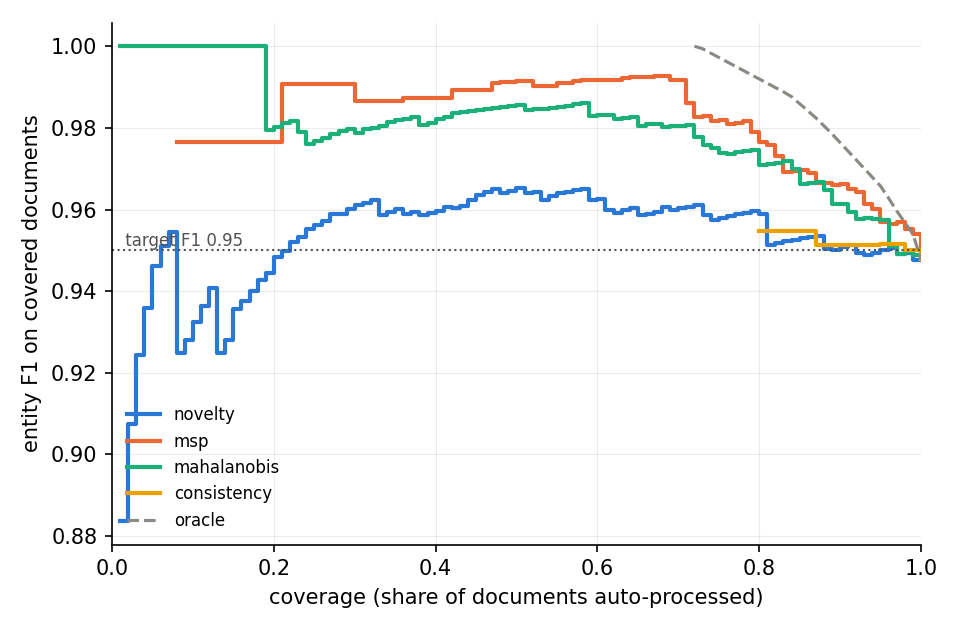

,coverage_at_target,aurc,f1_at_full_coverage,exact_at_full_coverage
novelty,0.96,0.047,0.948,0.72
msp,0.99,0.017,0.948,0.72
mahalanobis,0.96,0.020,0.948,0.72
consistency,0.98,0.046,0.948,0.72
oracle,0.99,0.006,0.948,0.72


In [68]:
routed = {'cord_layoutlmv3_j0.0_k0.0_a0.0_c0.0_s0': 'test', 'cord_disjoint_layoutlmv3_j0.0_k0.0_a0.0_c0.0_s0': 'test',
          'wildreceipt_layoutlmv3_j0.0_k0.0_a0.0_c0.0_s0': 'test'}
if RUN_DOCILE:
    routed['docile_layoutlmv3_j0.0_k0.0_a0.0_c0.0_s0'] = 'val'
for name, split in routed.items():
    route(RUNS / name, split, target=0.95)

RUN = RUNS / 'cord_layoutlmv3_j0.0_k0.0_a0.0_c0.0_s0'
display(Image(str(RUN / 'routing_test' / 'risk_coverage.png')))
pd.DataFrame(json.loads((RUN / 'routing_test' / 'summary.json').read_text())['signals']).T.round(3)

In [69]:
coverage = {run.parent.parent.name + ' · ' + run.parent.name.removeprefix('routing_'):
            {k: v['coverage_at_target'] for k, v in json.loads(run.read_text())['signals'].items()}
            for run in sorted(RUNS.glob('*/routing_*/summary.json'))}
print('Share of documents that can skip a person while F1 stays at the target:')
pd.DataFrame(coverage).T.style.format('{:.0%}')

Share of documents that can skip a person while F1 stays at the target:


,novelty,msp,mahalanobis,consistency,oracle
cord_disjoint_layoutlmv3_j0.0_k0.0_a0.0_c0.0_s0 · test,32%,72%,54%,68%,92%
cord_layoutlmv3_j0.0_k0.0_a0.0_c0.0_s0 · test,96%,99%,96%,98%,99%
docile_layoutlmv3_j0.0_k0.0_a0.0_c0.0_s0 · val,0%,4%,0%,0%,28%
wildreceipt_layoutlmv3_j0.0_k0.0_a0.0_c0.0_s0 · test,21%,89%,94%,42%,99%


### 17.3 Two documents up close
The riskiest document by the Mahalanobis score, then the safest.

In [70]:
show(RUN, 'test', pick(RUN, 'test', 'riskiest', 1)[0])

field                        extracted                     conf  ok
menu.nm                      BASO TAHU                     1.00  ✓
menu.price                   *46000                        0.49  ✓
menu.nm                      NASI PUTIH                    1.00  ✓
menu.price                   *6000                         0.51  ✓
menu.nm                      BASO TAHU                     1.00  ✓
menu.discountprice           *46000                        0.41  ✗
menu.cnt                     2x                            1.00  ✓
menu.unitprice               6000                          1.00  ✓
menu.nm                      NASI PUTIH                    1.00  ✓
menu.price                   *12000                        0.42  ✓
total.menutype_cnt           50 -                          0.68  ✓
total.creditcardprice        *110000                       0.89  ✗
menu.price                   (missed) *46000             
total.cashprice              (missed) *110000            

mahalanobis

In [71]:
show(RUN, 'test', pick(RUN, 'test', 'safest', 1)[0])

field                        extracted                     conf  ok
menu.cnt                     1                             1.00  ✓
menu.nm                      EGG TART                      1.00  ✓
menu.price                   13,000                        1.00  ✓
menu.cnt                     2                             1.00  ✓
menu.nm                      CHOCO CUS ARD PASTRY          1.00  ✓
menu.price                   24,000                        1.00  ✓
menu.cnt                     1                             1.00  ✓
menu.nm                      REDBEAN BREAD                 1.00  ✓
menu.price                   9,000                         1.00  ✓
total.total_price            46,000                        1.00  ✓
total.cashprice              50,000                        1.00  ✓
total.changeprice            4,000                         1.00  ✓
check items+tax+service=total        holds

mahalanobis risk 14.592 vs cut-off 75.541 (auto-processes 96% of documents at F1 ≥ 0

### 17.4 DocILE official scores
With DocILE downloaded, the official scorer compares fields by position, for each layout group.

In [72]:
if RUN_DOCILE:
    for run in sorted(RUNS.glob('docile_*')):
        report = evaluate_run(run, str(DOCILE_RAW))['val']['docile_kile']
        print(run.name, {k: round(v['f1'], 4) for k, v in report.items() if isinstance(v, dict)})

Run matching for documents: 100%|██████████| 500/500 [00:14<00:00, 33.43it/s]


docile_bros_j0.0_k0.0_a0.0_c0.0_s0 {'all': 0.531, 'zero-shot': 0.4725, 'few-shot': 0.5265, 'many-shot': 0.5552}


Run matching for documents: 100%|██████████| 500/500 [00:15<00:00, 33.28it/s]


docile_layoutlmv3_j0.05_k0.0_a0.0_c0.0_s0 {'all': 0.5246, 'zero-shot': 0.4742, 'few-shot': 0.4896, 'many-shot': 0.5573}


Run matching for documents: 100%|██████████| 500/500 [00:15<00:00, 33.13it/s]


...

docile_layoutlmv3_j0.0_k0.0_a0.1_c0.1_s0 {'all': 0.5192, 'zero-shot': 0.4651, 'few-shot': 0.4998, 'many-shot': 0.5475}


Run matching for documents: 100%|██████████| 500/500 [00:14<00:00, 33.62it/s]


docile_layoutlmv3_j0.0_k0.5_a0.0_c0.0_s0 {'all': 0.5171, 'zero-shot': 0.4796, 'few-shot': 0.4539, 'many-shot': 0.556}


Run matching for documents: 100%|██████████| 500/500 [00:15<00:00, 31.93it/s]


docile_roberta_j0.0_k0.0_a0.0_c0.0_s0 {'all': 0.5021, 'zero-shot': 0.4282, 'few-shot': 0.4431, 'many-shot': 0.5532}


## Where everything lives

| Item | Location |
|---|---|
| This notebook | github.com/AviDip/doc-extraction |
| The same code as a package, with tests | branch `source` of that repository |
| Datasets | CORD (CC BY 4.0, Hugging Face), WildReceipt (OpenMMLab), DocILE (token from docile.rossum.ai) |

In [73]:
SIGNALS = ("novelty", "msp", "mahalanobis", "consistency")  # the oracle needs labels, so it cannot set a cut-off


def cutoff(risk, counts, target):
    """The largest risk at which the documents processed automatically still
    reach the target F1, or -inf if even the safest group misses it."""
    order = np.argsort(risk, kind="stable")
    r, cum = risk[order], np.cumsum(counts[order], axis=0)
    ends = np.flatnonzero(np.r_[r[1:] != r[:-1], True])
    passing = [e for e in ends if prf(*cum[e])["f1"] >= target]
    return float(r[passing[-1]]) if passing else -np.inf


def fixed_cutoff(chosen_on, applied_to, target):
    """Choose each signal's cut-off on one set of documents, then apply it unchanged to another."""
    report = {}
    for name in SIGNALS:
        cut = cutoff(chosen_on[name], chosen_on["counts"], target)
        auto = applied_to[name] <= cut
        report[name] = {
            "auto_processed": float(auto.mean()),
            "f1_auto": prf(*applied_to["counts"][auto].sum(axis=0))["f1"] if auto.any() else float("nan"),
            "f1_to_person": prf(*applied_to["counts"][~auto].sum(axis=0))["f1"] if (~auto).any() else float("nan"),
        }
    return report


def signals_of(run, split):
    route(RUNS / run, split, target=0.95)
    return dict(np.load(RUNS / run / f'routing_{split}' / 'signals.npz'))

deployments = {
    'CORD': fixed_cutoff(signals_of('cord_layoutlmv3_j0.0_k0.0_a0.0_c0.0_s0', 'validation'), signals_of('cord_layoutlmv3_j0.0_k0.0_a0.0_c0.0_s0', 'test'), 0.95),
    'CORD, new shops': fixed_cutoff(signals_of('cord_disjoint_layoutlmv3_j0.0_k0.0_a0.0_c0.0_s0', 'validation'), signals_of('cord_disjoint_layoutlmv3_j0.0_k0.0_a0.0_c0.0_s0', 'test'), 0.95),
    'WildReceipt, familiar → new shops': fixed_cutoff(signals_of('wildreceipt_layoutlmv3_j0.0_k0.0_a0.0_c0.0_s0', 'validation'), signals_of('wildreceipt_layoutlmv3_j0.0_k0.0_a0.0_c0.0_s0', 'test'), 0.95),
}
if RUN_DOCILE:
    s = signals_of('docile_layoutlmv3_j0.0_k0.0_a0.0_c0.0_s0', 'val')
    first = np.random.default_rng(0).permutation(len(s['counts'])) < len(s['counts']) // 2
    deployments['DocILE, half → half'] = fixed_cutoff({k: v[first] for k, v in s.items()}, {k: v[~first] for k, v in s.items()}, 0.95)

table = pd.DataFrame({(d, sig): r for d, rep in deployments.items() for sig, r in rep.items()}).T
table.style.format({'auto_processed': '{:.0%}', 'f1_auto': '{:.3f}', 'f1_to_person': '{:.3f}'})